# VizWiz QLoRA Fine-Tuning and Evaluation Pipeline

This notebook implements the full training and evaluation pipeline for the quality-gated hybrid edge-cloud VQA assistant described in the report.

## Pipeline Overview

| Cell | Description |
|---|---|
| 1 | Environment setup — Drive mount, package installation, seeds |
| 2 | Configuration — central CONFIG dictionary |
| 3 | Data verification — VizWiz-VQA annotations and images |
| 4 | Quality gate — deterministic blur/dark/bright screening |
| 5 | Training set construction — gate-passed samples with majority-vote labels |
| 6 | Vision encoder pixel constraints |
| 7 | Model loading and QLoRA setup |
| 8 | Dataset and DataLoader setup |
| 9 | Resumable QLoRA training loop |
| 10 | Zero-shot baseline evaluation |
| 11 | Fine-tuned model evaluation |
| 12 | Cross-lingual verification |
| 13 | Model export and endpoint handler |
| 14 | Gate-disabled evaluation |

## Prerequisites
- Google Colab with GPU runtime (T4 or better recommended)
- VizWiz-VQA train/val images and annotations uploaded to Google Drive under `vizwiz_qwen/data/`
- Hugging Face account with a write-access token stored in Colab Secrets as `HF_TOKEN`

## Data access and Reproduction

The VizWiz-VQA dataset is not included in this submission due to its size and licensing terms. To re-run this notebook from scratch, download the following from the official VizWiz-VQA source (https://vizwiz.org/tasks-and-datasets/vqa/) and place them under vizwiz_qwen/data/ on Google Drive:

- Training and validation images → data/images/train/ and data/images/val/
- Annotation files (train.json, val.json) → data/annotations/

The gate-passed training files (train_processed.json, val_processed.json) are generated automatically by Cell 5 from the downloaded data and the quality-gate results; they are not included in the submission, as they contain VizWiz question and answer text.

Full re-training is not required for verification. Cached evaluation results are provided in vizwiz_qwen/results/, and the quality-gate cache is provided in vizwiz_qwen/gate_cache/; the notebook loads these directly when present, allowing the reported results to be verified without re-running the multi-hour fine-tuning.



## Cell 1: Environment Setup

This cell performs the following setup steps:
- Mounts Google Drive to access datasets, checkpoints, and results
- Installs all required Python packages with pinned versions for reproducibility
- Sets random seeds (42) across Python, NumPy, and PyTorch for deterministic behaviour
- Creates the required Drive directory structure if not already present
- Verifies installed package versions and folder existence


In [1]:
from pathlib import Path
import importlib.metadata as metadata
import os
import random

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as exc:
    raise RuntimeError("This notebook is intended for Google Colab. Drive mount failed.") from exc

%pip install -q \
    "transformers==4.51.3" \
    "peft==0.15.2" \
    "bitsandbytes==0.45.5" \
    "accelerate==1.6.0" \
    "qwen-vl-utils==0.0.10" \
    "datasets==3.5.0" \
    "opencv-python-headless==4.11.0.86" \
    "pillow==11.1.0" \
    "pandas==2.2.2" \
    "tqdm==4.67.1" \
    "langdetect==1.0.9"

import numpy as np
import torch

BOOTSTRAP_SEED = 42
random.seed(BOOTSTRAP_SEED)
np.random.seed(BOOTSTRAP_SEED)
torch.manual_seed(BOOTSTRAP_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(BOOTSTRAP_SEED)

drive_root = Path("/content/drive/MyDrive/vizwiz_qwen")
required_dirs = [
    drive_root / "data" / "images" / "train",
    drive_root / "data" / "images" / "val",
    drive_root / "gate_cache",
    drive_root / "checkpoints" / "latest",
    drive_root / "checkpoints" / "export",
    drive_root / "results",
]
for path in required_dirs:
    path.mkdir(parents=True, exist_ok=True)

installed_packages = [
    "transformers",
    "peft",
    "bitsandbytes",
    "accelerate",
    "qwen-vl-utils",
    "datasets",
    "opencv-python-headless",
    "pillow",
    "pandas",
    "tqdm",
    "langdetect",
]

print("\nInstalled package versions:")
for package_name in installed_packages:
    try:
        print(f"  {package_name}: {metadata.version(package_name)}")
    except metadata.PackageNotFoundError:
        print(f"  {package_name}: not found")

print("\nRequired Drive folders:")
for path in required_dirs:
    print(f"  {path} -> exists={path.exists()}")

print("Cell 1 complete. Packages installed, folders checked, and seeds set.")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 55.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 156.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 411.1/411.1 kB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.1/76.1 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.7/354.7 kB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4

## Cell 2: Configuration

This cell defines the central `CONFIG` dictionary that controls all aspects of the pipeline, including:

- **Model:** Base model name (`Qwen2.5-VL-3B-Instruct`) and image preprocessing parameters (resize to 640px)
- **Quality gate thresholds:** Blur (< 100.0), darkness (< 34.0), overexposure (> 0.2312)
- **QLoRA settings:** 4-bit NF4 quantisation, LoRA rank 16, alpha 32, target attention projections
- **Training hyperparameters:** Learning rate, epochs, batch size, gradient accumulation, warmup steps, checkpoint interval
- **Evaluation settings:** Max new tokens (10), answer types, VQA normalisation rules
- **Cross-lingual settings:** Supported languages (EN, ES, FR), 40-sample evaluation set
- **File paths:** All input/output paths derived from Drive root

All downstream cells reference `CONFIG` rather than hardcoded values, ensuring a single point of control for reproducibility.

In [2]:
from pathlib import Path
import pprint
import random

import numpy as np
import torch


CONFIG = {
    "model_name": "Qwen/Qwen2.5-VL-3B-Instruct",
    "resize_long_side": 640,
    "blur_threshold": 100.0,
    "dark_threshold": 34.0,
    "bright_threshold": 0.2312,
    "saturation_level": 245,
    "load_in_4bit": True,
    "bnb_4bit_compute_dtype": "bfloat16",
    "bnb_4bit_quant_type": "nf4",
    "bnb_4bit_use_double_quant": True,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "lora_target_modules": ["q_proj", "k_proj", "v_proj", "o_proj"],
    "learning_rate": 1e-4,
    "num_epochs": 2,
    "per_device_batch_size": 1,
    "gradient_accumulation_steps": 16,
    "warmup_steps": 100,
    "checkpoint_every_steps": 500,
    "max_new_tokens_eval": 10,
    "seed": 42,
    "supported_languages": ["en", "es", "fr"],
    "language_names": {"en": "English", "es": "Spanish", "fr": "French"},
    "system_prompt": "You are a helpful assistant for visually impaired users. Answer the question about the image briefly and directly. Always answer in the same language as the question. If the image does not contain enough information to answer the question, reply exactly with the word: unanswerable",
    "drive_root": "/content/drive/MyDrive/vizwiz_qwen",
    "gate_flush_every": 200,
    "gate_columns": ["image_name", "split", "lap_var", "mean_brightness", "overexp_fraction", "passed", "flaw"],
    "gate_rejection_warning_min": 0.25,
    "gate_rejection_warning_max": 0.55,
    "processed_json_files": {"train": "train_processed.json", "val": "val_processed.json"},
    "checkpoint_state_file": "trainer_state.pt",
    "checkpoint_optimizer_file": "optimizer.pt",
    "checkpoint_adapter_config_file": "adapter_config.json",
    "checkpoint_adapter_weight_files": ["adapter_model.safetensors", "adapter_model.bin"],
    "training_log_file": "training_log.csv",
    "training_log_columns": ["epoch", "global_step", "train_loss"],
    "oom_gradient_accumulation_steps": 32,
    "oom_batch_size": 1,
    "trainable_param_min": 5_000_000,
    "trainable_param_max": 80_000_000,
    "vision_module_name_fragments": ["visual", "vision", "vision_tower", "vision_model"],
    "tokenizer_padding_side": "right",
    "dataloader_num_workers": 2,
    "dataloader_pin_memory": True,
    "eval_chunk_size": 100,
    "answer_types": ["yes/no", "number", "other", "unanswerable"],
    "zeroshot_predictions_file": "zeroshot_predictions.json",
    "zeroshot_scores_file": "zeroshot_scores.json",
    "finetuned_predictions_file": "finetuned_predictions.json",
    "finetuned_scores_file": "finetuned_scores.json",
    "prediction_key_fields": ["image_name", "question"],
    "vqa_articles": ["a", "an", "the"],
    "punctuation_regex": r"[^\w\s]",
    "eval_adapter_name": "finetuned_eval",
    "checksum_min_delta": 1e-8,
    "crosslingual_sample_count": 40,
    "crosslingual_predictions_file": "crosslingual.json",
    "short_answer_word_threshold": 3,
    "short_answer_language_keywords": {
        "en": ["a", "an", "the", "yes", "no", "red", "blue", "green", "black", "white", "yellow", "orange", "pink", "brown", "gray", "one", "two", "three", "four", "five"],
        "es": ["el", "la", "los", "las", "un", "una", "si", "no", "rojo", "azul", "verde", "negro", "blanco", "amarillo", "naranja", "marron", "gris", "uno", "dos", "tres"],
        "fr": ["le", "la", "les", "un", "une", "oui", "non", "rouge", "bleu", "vert", "noir", "blanc", "jaune", "orange", "marron", "gris", "un", "deux", "trois"],
    },
    "export_torch_dtype": "float16",
    "export_max_shard_size": "4GB",
    "handler_file": "handler.py",
    "handler_requirements_file": "requirements.txt",
}

drive_root = CONFIG["drive_root"]
CONFIG["paths"] = {
    "data_dir": f"{drive_root}/data",
    "annotations_dir": f"{drive_root}/data/annotations",
    "train_image_dir": f"{drive_root}/data/images/train",
    "val_image_dir": f"{drive_root}/data/images/val",
    "gate_cache_dir": f"{drive_root}/gate_cache",
    "gate_results_csv": f"{drive_root}/gate_cache/gate_results.csv",
    "checkpoint_latest_dir": f"{drive_root}/checkpoints/latest",
    "checkpoint_export_dir": f"{drive_root}/checkpoints/export",
    "results_dir": f"{drive_root}/results",
    "train_processed_json": f"{drive_root}/data/train_processed.json",
    "val_processed_json": f"{drive_root}/data/val_processed.json",
    "train_annotation_json": f"{drive_root}/data/annotations/train.json",
    "val_annotation_json": f"{drive_root}/data/annotations/val.json",
}
CONFIG["paths"]["training_log_csv"] = f"{CONFIG['paths']['results_dir']}/{CONFIG['training_log_file']}"
CONFIG["paths"]["zeroshot_predictions_json"] = f"{CONFIG['paths']['results_dir']}/{CONFIG['zeroshot_predictions_file']}"
CONFIG["paths"]["zeroshot_scores_json"] = f"{CONFIG['paths']['results_dir']}/{CONFIG['zeroshot_scores_file']}"
CONFIG["paths"]["finetuned_predictions_json"] = f"{CONFIG['paths']['results_dir']}/{CONFIG['finetuned_predictions_file']}"
CONFIG["paths"]["finetuned_scores_json"] = f"{CONFIG['paths']['results_dir']}/{CONFIG['finetuned_scores_file']}"
CONFIG["paths"]["crosslingual_json"] = f"{CONFIG['paths']['results_dir']}/{CONFIG['crosslingual_predictions_file']}"


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def dtype_from_config(dtype_name):
    if not hasattr(torch, dtype_name):
        raise ValueError(f"Unsupported torch dtype in CONFIG: {dtype_name}")
    return getattr(torch, dtype_name)


for key in [
    "data_dir",
    "annotations_dir",
    "train_image_dir",
    "val_image_dir",
    "gate_cache_dir",
    "checkpoint_latest_dir",
    "checkpoint_export_dir",
    "results_dir",
]:
    Path(CONFIG["paths"][key]).mkdir(parents=True, exist_ok=True)

set_all_seeds(CONFIG["seed"])
pprint.pp(CONFIG)
print("Cell 2 complete. CONFIG is defined and Drive subpaths are derived.")

{'model_name': 'Qwen/Qwen2.5-VL-3B-Instruct',
 'resize_long_side': 640,
 'blur_threshold': 100.0,
 'dark_threshold': 34.0,
 'bright_threshold': 0.2312,
 'saturation_level': 245,
 'load_in_4bit': True,
 'bnb_4bit_compute_dtype': 'bfloat16',
 'bnb_4bit_quant_type': 'nf4',
 'bnb_4bit_use_double_quant': True,
 'lora_r': 16,
 'lora_alpha': 32,
 'lora_dropout': 0.05,
 'lora_target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj'],
 'learning_rate': 0.0001,
 'num_epochs': 2,
 'per_device_batch_size': 1,
 'gradient_accumulation_steps': 16,
 'warmup_steps': 100,
 'checkpoint_every_steps': 500,
 'max_new_tokens_eval': 10,
 'seed': 42,
 'supported_languages': ['en', 'es', 'fr'],
 'language_names': {'en': 'English', 'es': 'Spanish', 'fr': 'French'},
 'system_prompt': 'You are a helpful assistant for visually impaired users. '
                  'Answer the question about the image briefly and directly. '
                  'Always answer in the same language as the question. If the '
              

## Cell 3: Data Verification

This cell verifies that all required VizWiz-VQA files are present on Google Drive before any processing begins:

- **Path checks:** Confirms that train/val annotation JSON files and image directories exist at the expected Drive locations; raises a `FileNotFoundError` with the exact missing path if not found
- **Annotation validation:** Checks that each annotation file contains a list of entries with the required fields (`image`, `question`, `answers`, `answer_type`, `answerable`) and that each entry has exactly 10 crowdsourced answers
- **Image count summary:** Counts how many images referenced in the annotations are actually present in the image directories and reports any missing files


In [4]:
from pathlib import Path
import json


required_paths = {
    "train_annotation_json": Path(CONFIG["paths"]["train_annotation_json"]),
    "val_annotation_json": Path(CONFIG["paths"]["val_annotation_json"]),
    "train_image_dir": Path(CONFIG["paths"]["train_image_dir"]),
    "val_image_dir": Path(CONFIG["paths"]["val_image_dir"]),
}

missing_paths = []
for key, path in required_paths.items():
    if key.endswith("_dir"):
        exists = path.is_dir()
    else:
        exists = path.is_file()
    if not exists:
        print(f"Missing required path: {path}")
        missing_paths.append(path)

if missing_paths:
    missing_list = "\n".join(str(path) for path in missing_paths)
    raise FileNotFoundError(
        f"{missing_list}"
    )


def load_and_validate_annotations(annotation_path, split_name):
    with Path(annotation_path).open("r", encoding="utf-8") as handle:
        annotations = json.load(handle)

    if not isinstance(annotations, list):
        raise RuntimeError(f"{split_name}.json must contain a list of annotation entries.")
    if not annotations:
        raise RuntimeError(f"{split_name}.json is empty; expected at least one annotation entry.")

    first_entry = annotations[0]
    if not isinstance(first_entry, dict):
        raise RuntimeError(f"First entry in {split_name}.json must be a dictionary.")

    for field in ["image", "question", "answers"]:
        if field not in first_entry:
            raise RuntimeError(f"First entry in {split_name}.json is missing required field: {field}")

    answers = first_entry["answers"]
    if not isinstance(answers, list):
        raise RuntimeError(f"First entry in {split_name}.json has invalid answers field: expected a list.")
    if len(answers) != 10:
        raise RuntimeError(f"First entry in {split_name}.json has invalid answers field: expected 10 answers, found {len(answers)}.")
    for answer_index, answer_item in enumerate(answers):
        if not isinstance(answer_item, dict):
            raise RuntimeError(f"Answer {answer_index} in first {split_name}.json entry must be a dictionary.")
        if "answer" not in answer_item:
            raise RuntimeError(f"Answer {answer_index} in first {split_name}.json entry is missing required key: answer")

    for field in ["answer_type", "answerable"]:
        if field not in first_entry:
            raise RuntimeError(f"First entry in {split_name}.json is missing required field: {field}")

    return annotations


def count_present_images(annotations, image_dir):
    image_dir = Path(image_dir)
    expected_paths = [image_dir / entry["image"] for entry in annotations if isinstance(entry, dict) and "image" in entry]
    present_count = sum(path.is_file() for path in expected_paths)
    missing_paths = [path for path in expected_paths if not path.is_file()]
    return len(expected_paths), present_count, missing_paths


def print_image_count_summary(split_label, expected_count, present_count, missing_paths, image_dir, annotation_path):
    print(f"{split_label}: expected image count from annotations vs present: {expected_count} vs {present_count}")
    if missing_paths:
        print(f"WARNING: {split_label} is missing {len(missing_paths)} images.")
        print(f"Check image folder: {image_dir}")
        print(f"Check annotation file: {annotation_path}")
        preview_count = min(len(missing_paths), 20)
        print(f"First {preview_count} missing image paths:")
        for path in missing_paths[:preview_count]:
            print(f"  {path}")
        if len(missing_paths) > preview_count:
            print(f"  ... and {len(missing_paths) - preview_count} more missing images.")


train_annotations = load_and_validate_annotations(required_paths["train_annotation_json"], "train")
val_annotations = load_and_validate_annotations(required_paths["val_annotation_json"], "val")

train_expected, train_present, train_missing = count_present_images(
    train_annotations,
    required_paths["train_image_dir"],
)
val_expected, val_present, val_missing = count_present_images(
    val_annotations,
    required_paths["val_image_dir"],
)

print_image_count_summary(
    "Train",
    train_expected,
    train_present,
    train_missing,
    required_paths["train_image_dir"],
    required_paths["train_annotation_json"],
)
print_image_count_summary(
    "Val",
    val_expected,
    val_present,
    val_missing,
    required_paths["val_image_dir"],
    required_paths["val_annotation_json"],
)

print(f"Cell 3 complete. Train: {train_expected} annotations, {train_present} images present. Val: {val_expected} annotations, {val_present} images present.")


Train: expected image count from annotations vs present: 20523 vs 20523
Val: expected image count from annotations vs present: 4319 vs 4319
Cell 3 complete. Train: 20523 annotations, 20523 images present. Val: 4319 annotations, 4319 images present.


## Cell 4: On-Device Quality Gate

This cell runs the deterministic image-quality gate across all train and validation images, implementing the three-metric screening described in Section 3.2.2:

- **Blur:** Laplacian variance < 100.0
- **Dark:** Mean grayscale brightness < 34.0
- **Bright:** Overexposed pixel fraction > 0.2312

Each image is resized so its longest side equals 640 pixels before metric computation, matching the calibration preprocessing. The gate applies OR logic — an image is rejected if any single check fails — and the detected flaw is recorded.

Results are written incrementally to a CSV file every 200 images (`gate_flush_every`), enabling the cell to resume from where it left off if the session is interrupted. A warning is raised if the overall rejection rate falls outside the expected 25–55% range, indicating a preprocessing mismatch.

**Output:** `gate_results.csv` containing per-image metrics, pass/fail status, and flaw type for all train and validation images.

In [5]:
from pathlib import Path
import csv
import json

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


def load_annotations(split):
    annotation_path = CONFIG["paths"][f"{split}_annotation_json"]
    with open(annotation_path, "r", encoding="utf-8") as handle:
        return json.load(handle)


def resize_long_side_if_needed(image_bgr):
    height, width = image_bgr.shape[:2]
    longest_side = max(height, width)
    if longest_side <= CONFIG["resize_long_side"]:
        return image_bgr
    scale = CONFIG["resize_long_side"] / float(longest_side)
    new_width = int(round(width * scale))
    new_height = int(round(height * scale))
    return cv2.resize(image_bgr, (new_width, new_height), interpolation=cv2.INTER_AREA)


def run_quality_gate(image_path):
    image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise RuntimeError(f"OpenCV could not read image: {image_path}")

    resized = resize_long_side_if_needed(image_bgr)
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    lap_var = float(laplacian.var())
    mean_brightness = float("nan")
    overexp_fraction = float("nan")
    if lap_var < CONFIG["blur_threshold"]:
        return lap_var, mean_brightness, overexp_fraction, False, "blur"

    mean_brightness = float(gray.mean())
    if mean_brightness < CONFIG["dark_threshold"]:
        return lap_var, mean_brightness, overexp_fraction, False, "dark"

    overexp_fraction = float((gray >= CONFIG["saturation_level"]).sum() / gray.size)
    if overexp_fraction > CONFIG["bright_threshold"]:
        return lap_var, mean_brightness, overexp_fraction, False, "bright"

    return lap_var, mean_brightness, overexp_fraction, True, ""


def load_existing_gate_results(csv_path):
    csv_path = Path(csv_path)
    if not csv_path.exists() or csv_path.stat().st_size == 0:
        return pd.DataFrame(columns=CONFIG["gate_columns"]), set()
    frame = pd.read_csv(csv_path)
    missing_columns = set(CONFIG["gate_columns"]) - set(frame.columns)
    if missing_columns:
        raise RuntimeError(f"Gate CSV is missing required columns: {sorted(missing_columns)}")
    processed = set(zip(frame["split"].astype(str), frame["image_name"].astype(str)))
    return frame, processed


def append_gate_rows(csv_path, rows):
    if not rows:
        return
    csv_path = Path(csv_path)
    write_header = not csv_path.exists() or csv_path.stat().st_size == 0
    with csv_path.open("a", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=CONFIG["gate_columns"])
        if write_header:
            writer.writeheader()
        writer.writerows(rows)


all_items = []
for split in ["train", "val"]:
    annotations = load_annotations(split)
    image_dir = Path(CONFIG["paths"][f"{split}_image_dir"])
    for item in annotations:
        image_path = image_dir / item["image"]
        if not image_path.exists():
            raise FileNotFoundError(f"Missing image for quality gate: {image_path}. Re-run Cell 3.")
        all_items.append((split, item["image"], image_path))

existing_frame, processed_keys = load_existing_gate_results(CONFIG["paths"]["gate_results_csv"])
pending_items = [(split, image_name, path) for split, image_name, path in all_items if (split, image_name) not in processed_keys]

rows_buffer = []
done_count = 0
skipped_count = len(all_items) - len(pending_items)
for split, image_name, image_path in tqdm(pending_items, desc="Quality gate"):
    lap_var, mean_brightness, overexp_fraction, passed, flaw = run_quality_gate(image_path)
    rows_buffer.append({
        "image_name": image_name,
        "split": split,
        "lap_var": lap_var,
        "mean_brightness": mean_brightness,
        "overexp_fraction": overexp_fraction,
        "passed": passed,
        "flaw": flaw,
    })
    done_count += 1
    if len(rows_buffer) >= CONFIG["gate_flush_every"]:
        append_gate_rows(CONFIG["paths"]["gate_results_csv"], rows_buffer)
        rows_buffer = []

append_gate_rows(CONFIG["paths"]["gate_results_csv"], rows_buffer)

gate_results = pd.read_csv(CONFIG["paths"]["gate_results_csv"])
passed_mask = gate_results["passed"].astype(str).str.lower().isin(["true", "1", "yes"])
total_processed = len(gate_results)
passed_count = int(passed_mask.sum())
rejected_count = total_processed - passed_count
flaw_breakdown = gate_results.loc[~passed_mask, "flaw"].value_counts().to_dict()
rejection_rate = rejected_count / total_processed if total_processed else 0.0

print("\nQuality gate summary:")
print(f"  total processed: {total_processed}")
print(f"  passed: {passed_count}")
print(f"  rejected: {rejected_count}")
for flaw_name in ["blur", "dark", "bright"]:
    print(f"  {flaw_name}: {int(flaw_breakdown.get(flaw_name, 0))}")
print(f"  rejection rate: {rejection_rate:.2%}")
if not (CONFIG["gate_rejection_warning_min"] <= rejection_rate <= CONFIG["gate_rejection_warning_max"]):
    print("WARNING: Gate rejection rate is outside 25%-55%. Preprocessing may not match the calibrated thresholds. Verify the resize step.")

print(f"Cell 4 complete. {done_count} images done, {skipped_count} images skipped.")

Quality gate: 0it [00:00, ?it/s]


Quality gate summary:
  total processed: 24842
  passed: 15205
  rejected: 9637
  blur: 9398
  dark: 60
  bright: 179
  rejection rate: 38.79%
Cell 4 complete. 0 images done, 24842 images skipped.


## Cell 5: Training Set Construction

This cell builds the gate-passed training and validation sets described in Section 3.2.1.3:

- **Gate filtering:** Loads `gate_results.csv` from Cell 4 and retains only images that passed all three quality checks
- **Answer selection:** For each retained sample, selects the majority answer from 10 crowdsourced responses using a `Counter`; ties are broken alphabetically. `unanswerable` is retained as a valid target label
- **Output format:** Each processed entry contains `image_name`, `question`, `target_answer`, `answer_type`, and all 10 `all_answers`
- **Resume support:** If the processed JSON files already exist on Drive, they are loaded directly rather than rebuilt

**Output:** `train_processed.json` and `val_processed.json` containing only gate-passed samples with majority-vote target answers.

In [6]:
from collections import Counter
from pathlib import Path
import json

import pandas as pd


def load_json_file(json_path):
    with Path(json_path).open("r", encoding="utf-8") as handle:
        return json.load(handle)


def save_json_file(json_path, payload):
    json_path = Path(json_path)
    json_path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = json_path.with_suffix(json_path.suffix + ".tmp")
    with temporary_path.open("w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2)
    temporary_path.replace(json_path)


def clean_target_answer(answer):
    text = str(answer).strip()
    if not text or text.casefold() == "unanswerable":
        return "unanswerable"
    return text


def select_majority_answer(answers):
    cleaned_answers = []
    for answer_item in answers:
        if isinstance(answer_item, dict):
            cleaned_answers.append(clean_target_answer(answer_item.get("answer", "")))
        else:
            cleaned_answers.append(clean_target_answer(answer_item))

    if len(cleaned_answers) != 10:
        raise RuntimeError(f"Expected 10 human answers, found {len(cleaned_answers)}.")

    counts = Counter(cleaned_answers)
    best_count = max(counts.values())
    tied_answers = [answer for answer, count in counts.items() if count == best_count]
    return sorted(tied_answers, key=lambda value: value.casefold())[0]


def load_passed_gate_keys(gate_csv_path):
    gate_csv_path = Path(gate_csv_path)
    if not gate_csv_path.is_file():
        raise FileNotFoundError(f"Gate CSV not found: {gate_csv_path}. Run Cell 4 first.")

    frame = pd.read_csv(gate_csv_path)
    missing_columns = set(CONFIG["gate_columns"]) - set(frame.columns)
    if missing_columns:
        raise RuntimeError(f"Gate CSV is missing required columns: {sorted(missing_columns)}")

    passed_mask = frame["passed"].astype(str).str.lower().isin(["true", "1", "yes"])
    passed_frame = frame.loc[passed_mask, ["split", "image_name"]].copy()
    return set(zip(passed_frame["split"].astype(str), passed_frame["image_name"].astype(str)))


def build_processed_split(split, annotations, passed_keys):
    processed = []
    for entry in annotations:
        image_name = str(entry["image"])
        if (split, image_name) not in passed_keys:
            continue

        all_answers = []
        for answer_item in entry["answers"]:
            if isinstance(answer_item, dict):
                all_answers.append(clean_target_answer(answer_item.get("answer", "")))
            else:
                all_answers.append(clean_target_answer(answer_item))

        processed.append({
            "image_name": image_name,
            "question": str(entry["question"]).strip(),
            "target_answer": select_majority_answer(entry["answers"]),
            "answer_type": str(entry.get("answer_type", "other")),
            "all_answers": all_answers,
        })
    return processed


def load_or_build_processed_split(split, annotations, passed_keys):
    processed_path = Path(CONFIG["paths"][f"{split}_processed_json"])
    if processed_path.is_file() and processed_path.stat().st_size > 0:
        processed = load_json_file(processed_path)
        print(f"{split}: loaded existing processed file: {processed_path}")
        return processed, True

    processed = build_processed_split(split, annotations, passed_keys)
    save_json_file(processed_path, processed)
    print(f"{split}: wrote processed file: {processed_path}")
    return processed, False


train_annotations = load_json_file(CONFIG["paths"]["train_annotation_json"])
val_annotations = load_json_file(CONFIG["paths"]["val_annotation_json"])
passed_gate_keys = load_passed_gate_keys(CONFIG["paths"]["gate_results_csv"])

train_processed, train_loaded_existing = load_or_build_processed_split("train", train_annotations, passed_gate_keys)
val_processed, val_loaded_existing = load_or_build_processed_split("val", val_annotations, passed_gate_keys)

train_before = len(train_annotations)
val_before = len(val_annotations)
train_after = len(train_processed)
val_after = len(val_processed)
train_retained = (train_after / train_before * 100.0) if train_before else 0.0
val_retained = (val_after / val_before * 100.0) if val_before else 0.0
train_unanswerable = sum(item["target_answer"].casefold() == "unanswerable" for item in train_processed)
val_unanswerable = sum(item["target_answer"].casefold() == "unanswerable" for item in val_processed)

print("\nProcessed dataset summary:")
print(f"  train samples before gate: {train_before}")
print(f"  train samples after gate: {train_after}")
print(f"  train retained: {train_retained:.2f}%")
print(f"  train retained unanswerable samples: {train_unanswerable}")
print(f"  val samples before gate: {val_before}")
print(f"  val samples after gate: {val_after}")
print(f"  val retained: {val_retained:.2f}%")
print(f"  val retained unanswerable samples: {val_unanswerable}")

done_count = int(not train_loaded_existing) + int(not val_loaded_existing)
skipped_count = int(train_loaded_existing) + int(val_loaded_existing)
print(f"Cell 5 complete. {done_count} splits processed, {skipped_count} splits skipped.")



Starting Cell 5: building resumable gate-passed training and validation sets.
train: loaded existing processed file: /content/drive/MyDrive/vizwiz_qwen/data/train_processed.json
val: loaded existing processed file: /content/drive/MyDrive/vizwiz_qwen/data/val_processed.json

Processed dataset summary:
  train samples before gate: 20523
  train samples after gate: 12583
  train retained: 61.31%
  train retained unanswerable samples: 3756
  val samples before gate: 4319
  val samples after gate: 2622
  val retained: 60.71%
  val retained unanswerable samples: 949
Cell 5 complete. 0 splits processed, 2 splits skipped.


## Cell 6: Vision Encoder Pixel Constraints

This cell sets the pixel bounds for the Qwen2.5-VL dynamic-resolution vision encoder:

- **`max_pixels`:** 1,024 × 1,024 = 1,048,576 — upper limit on input resolution to control memory usage
- **`min_pixels`:** 224 × 224 = 50,176 — lower limit to preserve sufficient visual detail for inference

These bounds are passed to `process_vision_info` from `qwen-vl-utils` during both training and evaluation, ensuring consistent image preprocessing across all pipeline stages.

In [7]:
from qwen_vl_utils import process_vision_info
CONFIG["max_pixels"] = 1024 * 1024
CONFIG["min_pixels"] = 224 * 224

print(f"Max pixels set to: {CONFIG['max_pixels']} ({int(CONFIG['max_pixels']**0.5)}x{int(CONFIG['max_pixels']**0.5)} equivalent)")

Max pixels set to: 1048576 (1024x1024 equivalent)


## Cell 7: Model Loading and QLoRA Setup

This cell loads the base model and applies QLoRA adaptation as described in Section 3.2.3.2:

- **4-bit quantisation:** Loads `Qwen2.5-VL-3B-Instruct` in NF4 format with double quantisation and bfloat16 compute dtype, using BitsAndBytes
- **Vision encoder frozen:** All vision-related parameters are explicitly frozen before LoRA injection; a runtime check raises an error if any vision parameter is accidentally made trainable
- **LoRA injection:** Adapters are injected into language model attention projections only (`q_proj`, `k_proj`, `v_proj`, `o_proj`), excluding vision modules
- **Parameter validation:** Asserts that trainable parameter count falls within the expected range (5M–80M); raises an error if outside this range, catching misconfigured LoRA targets
- **Processor setup:** Loads the tokenizer with right-side padding and sets the pad token to EOS if not already defined


In [ ]:
import torch
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoProcessor, BitsAndBytesConfig

try:
    from transformers import Qwen2_5_VLForConditionalGeneration
except ImportError as exc:
    raise ImportError(
        "Qwen2_5_VLForConditionalGeneration is not available. "
        "Confirm that Cell 1 installed transformers==4.51.3."
    ) from exc


def module_name_is_vision_related(module_name):
    lowered = module_name.lower()
    return any(fragment.lower() in lowered for fragment in CONFIG["vision_module_name_fragments"])


def collect_language_lora_target_modules(model):
    target_leaf_names = set(CONFIG["lora_target_modules"])
    matched_module_names = []
    for module_name, module in model.named_modules():
        leaf_name = module_name.rsplit(".", 1)[-1]
        if leaf_name in target_leaf_names and not module_name_is_vision_related(module_name):
            matched_module_names.append(module_name)
    if not matched_module_names:
        raise RuntimeError(
            "No language LoRA target modules were found. "
            "Check CONFIG['lora_target_modules'] and the model architecture."
        )
    return sorted(set(matched_module_names))


def count_parameters(model):
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    total = sum(parameter.numel() for parameter in model.parameters())
    return trainable, total


def get_first_parameter_device(model):
    for parameter in model.parameters():
        return parameter.device
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def runtime_compute_dtype_from_config():
    configured_dtype = dtype_from_config(CONFIG["bnb_4bit_compute_dtype"])
    if (
        configured_dtype == torch.bfloat16
        and torch.cuda.is_available()
        and not torch.cuda.is_bf16_supported()
    ):
        print(
            "WARNING: CUDA device does not support bfloat16 efficiently. "
            "Switching to float16."
        )
        return torch.float16
    return configured_dtype


def load_model_and_processor_with_qlora():
    set_all_seeds(CONFIG["seed"])

    compute_dtype = runtime_compute_dtype_from_config()
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=CONFIG["load_in_4bit"],
        bnb_4bit_compute_dtype=compute_dtype,
        bnb_4bit_quant_type=CONFIG["bnb_4bit_quant_type"],
        bnb_4bit_use_double_quant=CONFIG["bnb_4bit_use_double_quant"],
    )

    loaded_processor = AutoProcessor.from_pretrained(
        CONFIG["model_name"],
    max_pixels=CONFIG["max_pixels"],
    min_pixels=CONFIG["min_pixels"]
)
    loaded_processor.tokenizer.padding_side = CONFIG["tokenizer_padding_side"]
    if loaded_processor.tokenizer.pad_token is None:
        loaded_processor.tokenizer.pad_token = loaded_processor.tokenizer.eos_token

    loaded_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        CONFIG["model_name"],
        quantization_config=quantization_config,
        torch_dtype=compute_dtype,
        device_map="auto",
        trust_remote_code=True,
    )
    loaded_model.config.use_cache = False

    for name, parameter in loaded_model.named_parameters():
        if module_name_is_vision_related(name):
            parameter.requires_grad_(False)

    loaded_model = prepare_model_for_kbit_training(
    loaded_model,
    use_gradient_checkpointing=False,
)

    lora_target_modules = collect_language_lora_target_modules(loaded_model)
    print(f"Matched {len(lora_target_modules)} language LoRA target modules.")
    print("First matched targets:")
    for module_name in lora_target_modules[:8]:
        print(f"  {module_name}")
    if len(lora_target_modules) > 8:
        print(f"  ... and {len(lora_target_modules) - 8} more")

    lora_config = LoraConfig(
        r=CONFIG["lora_r"],
        lora_alpha=CONFIG["lora_alpha"],
        target_modules=lora_target_modules,
        lora_dropout=CONFIG["lora_dropout"],
        bias="none",
        task_type="CAUSAL_LM",
    )
    loaded_model = get_peft_model(loaded_model, lora_config)

    trainable_parameters, total_parameters = count_parameters(loaded_model)
    print(f"Trainable parameters: {trainable_parameters:,}")
    print(f"Total parameters: {total_parameters:,}")
    print(f"Trainable percentage: {100.0 * trainable_parameters / total_parameters:.4f}%")

    if not (CONFIG["trainable_param_min"] <= trainable_parameters <= CONFIG["trainable_param_max"]):
        raise RuntimeError(
            "Trainable parameter count is outside the expected QLoRA range. "
            f"Found {trainable_parameters:,}; expected between "
            f"{CONFIG['trainable_param_min']:,} and {CONFIG['trainable_param_max']:,}. "
            "Too low usually means LoRA matched nothing. Too high usually means LoRA matched too much."
        )

    trainable_vision_parameters = [
        name for name, parameter in loaded_model.named_parameters()
        if parameter.requires_grad and module_name_is_vision_related(name)
    ]
    if trainable_vision_parameters:
        preview = trainable_vision_parameters[:10]
        raise RuntimeError(
            "Vision-related parameters are trainable, but the vision tower must remain frozen. "
            f"First offending parameters: {preview}"
        )

    return loaded_model, loaded_processor


model, processor = load_model_and_processor_with_qlora()
print(f"Model input device: {get_first_parameter_device(model)}")
print("Cell 7 complete. Model, processor, and QLoRA adapters are ready.")



tokenizer.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Matched 144 language LoRA target modules.
First matched targets:
  model.layers.0.self_attn.k_proj
  model.layers.0.self_attn.o_proj
  model.layers.0.self_attn.q_proj
  model.layers.0.self_attn.v_proj
  model.layers.1.self_attn.k_proj
  model.layers.1.self_attn.o_proj
  model.layers.1.self_attn.q_proj
  model.layers.1.self_attn.v_proj
  ... and 136 more
Trainable parameters: 7,372,800
Total parameters: 2,041,397,248
Trainable percentage: 0.3612%
Model input device: cuda:0
Cell 7 complete. Model, processor, and QLoRA adapters are ready.


In [10]:
print(f"image_processor max_pixels: {processor.image_processor.max_pixels}")
print(f"image_processor min_pixels: {processor.image_processor.min_pixels}")

image_processor max_pixels: 1048576
image_processor min_pixels: 50176


### Copy Training Data to Local Disk

Copies the VizWiz training image zip from Google Drive to local Colab storage for quicker extraction. Skips this step if the file already exists.

In [11]:
import shutil
from pathlib import Path

drive_zip = "/content/drive/MyDrive/vizwiz_qwen/data/downloads/train.zip"
local_zip = "/content/train.zip"

if not Path(local_zip).exists():
    print("Copying zip from Drive to local disk...")
    shutil.copy(drive_zip, local_zip)
    print(f"Done. Size: {Path(local_zip).stat().st_size / 1e9:.1f} GB")
else:
    print("Zip already on local disk.")

Copying zip from Drive to local disk...
Done. Size: 11.3 GB


In [12]:
import zipfile, os

print("Extracting train.zip to /content/train_images2...")
with zipfile.ZipFile("/content/train.zip", "r") as z:
    z.extractall("/content/train_images2")

count = len(os.listdir("/content/train_images2"))
print(f"Done: {count} images extracted")

Extracting train.zip to /content/train_images2...
Done: 1 images extracted


### Verify and Update Train Image Path

Counts extracted training images and updates `CONFIG["paths"]["train_image_dir"]` to point to the local extraction path.

In [14]:
import os

real_path = "/content/train_images2/train"
count = len(os.listdir(real_path))
print(f"Train images: {count}")
print("İlk 3 dosya:", os.listdir(real_path)[:3])


CONFIG["paths"]["train_image_dir"] = real_path
print(f"CONFIG updated: {CONFIG['paths']['train_image_dir']}")

Train images: 23954
İlk 3 dosya: ['VizWiz_train_00019391.jpg', 'VizWiz_train_00021774.jpg', 'VizWiz_train_00018733.jpg']
CONFIG updated: /content/train_images2/train


### DataLoader Configuration Check

Prints the active DataLoader and batch settings from `CONFIG` before training begins:

- `num_workers`: parallel data loading processes
- `pin_memory`: pinned memory for faster GPU transfer
- `per_device_batch_size`: samples per forward pass
- `max_pixels`: vision encoder input resolution cap


In [15]:
print(f"num_workers: {CONFIG['dataloader_num_workers']}")
print(f"pin_memory: {CONFIG['dataloader_pin_memory']}")
print(f"per_device_batch_size: {CONFIG['per_device_batch_size']}")
print(f"max_pixels: {CONFIG['max_pixels']}")

num_workers: 2
pin_memory: True
per_device_batch_size: 1
max_pixels: 1048576


### DataLoader Settings Override

Disables parallel data loading (`num_workers=0`) and pinned memory (`pin_memory=False`) to prevent worker deadlocks and memory errors common in the Colab environment.

In [16]:
CONFIG["dataloader_num_workers"] = 0
CONFIG["dataloader_pin_memory"] = False
print("Updated: num_workers=0, pin_memory=False")

Updated: num_workers=0, pin_memory=False


## Cell 8: Dataset and DataLoader Setup

This cell creates the PyTorch `Dataset` and `DataLoader` objects for training and validation:

- **`VizWizQwenDataset`:** Lazy-loading dataset that reads images on demand, applies the Qwen chat template, and constructs input/label tensors. Prompt tokens are masked (`labels = -100`) so that loss is computed only on the answer portion
- **`collate_qwen_vl_batch`:** Custom collation function that pads sequences to the longest item in each batch and concatenates vision tensors (`pixel_values`, `image_grid_thw`)
- **Reproducibility:** Each epoch's DataLoader uses a seeded `torch.Generator` (`seed + epoch_index`) to ensure shuffling is deterministic and resumable
- **DataLoaders:** Training loader shuffles samples per epoch; validation loader is unshuffled

**Output:** `train_dataset` and `val_dataset` loaded from gate-passed JSON files, with corresponding DataLoaders ready for the training loop.

In [17]:
from pathlib import Path
from PIL import Image
import math
import random

import numpy as np
from torch.utils.data import DataLoader, Dataset
from qwen_vl_utils import process_vision_info


class VizWizQwenDataset(Dataset):
    def __init__(self, samples, image_dir, processor, config):
        self.samples = list(samples)
        self.image_dir = Path(image_dir)
        self.processor = processor
        self.config = config

    def __len__(self):
        return len(self.samples)

    def build_prompt_messages(self, image, question):
        return [
            {
                "role": "system",
                "content": [{"type": "text", "text": self.config["system_prompt"]}],
            },
            {
                "role": "user",
                "content": [
                    {
    "type": "image",
    "image": image,
    "max_pixels": self.config["max_pixels"],
    "min_pixels": self.config["min_pixels"],
},
                    {"type": "text", "text": question},
                ],
            },
        ]

    def __getitem__(self, index):
        sample = self.samples[index]
        image_path = self.image_dir / sample["image_name"]
        if not image_path.is_file():
            raise FileNotFoundError(f"Image not found for dataset item: {image_path}")

        image = Image.open(image_path).convert("RGB")
        prompt_messages = self.build_prompt_messages(image, sample["question"])
        full_messages = prompt_messages + [
            {
                "role": "assistant",
                "content": [{"type": "text", "text": sample["target_answer"]}],
            }
        ]

        prompt_text = self.processor.apply_chat_template(
            prompt_messages,
            tokenize=False,
            add_generation_prompt=True,
        )
        full_text = self.processor.apply_chat_template(
            full_messages,
            tokenize=False,
            add_generation_prompt=False,
        )

        image_inputs, video_inputs = process_vision_info(prompt_messages)
        prompt_inputs = self.processor(
            text=[prompt_text],
            images=image_inputs,
            videos=video_inputs,
            padding=False,
            return_tensors="pt",
        )
        full_inputs = self.processor(
            text=[full_text],
            images=image_inputs,
            videos=video_inputs,
            padding=False,
            return_tensors="pt",
        )

        labels = full_inputs["input_ids"].clone()
        prompt_length = prompt_inputs["input_ids"].shape[1]
        labels[:, :prompt_length] = -100

        item = {
            "input_ids": full_inputs["input_ids"][0],
            "attention_mask": full_inputs["attention_mask"][0],
            "labels": labels[0],
            "metadata": sample,
        }
        for key, value in full_inputs.items():
            if key in {"input_ids", "attention_mask"}:
                continue
            item[key] = value
        return item


def seed_dataloader_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def collate_qwen_vl_batch(batch):
    pad_token_id = processor.tokenizer.pad_token_id
    if pad_token_id is None:
        pad_token_id = processor.tokenizer.eos_token_id

    max_length = max(item["input_ids"].shape[0] for item in batch)
    input_ids = torch.full((len(batch), max_length), pad_token_id, dtype=torch.long)
    attention_mask = torch.zeros((len(batch), max_length), dtype=torch.long)
    labels = torch.full((len(batch), max_length), -100, dtype=torch.long)

    for row_index, item in enumerate(batch):
        sequence_length = item["input_ids"].shape[0]
        input_ids[row_index, :sequence_length] = item["input_ids"]
        attention_mask[row_index, :sequence_length] = item["attention_mask"]
        labels[row_index, :sequence_length] = item["labels"]

    collated = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }

    tensor_keys = sorted(
        key for key in batch[0].keys()
        if key not in {"input_ids", "attention_mask", "labels", "metadata"}
    )
    for key in tensor_keys:
        values = [item[key] for item in batch if key in item and torch.is_tensor(item[key])]
        if not values:
            continue
        if key.endswith("grid_thw"):
            collated[key] = torch.cat(values, dim=0)
        else:
            collated[key] = torch.cat(values, dim=0)

    return collated


def create_train_dataloader_for_epoch(epoch_index=0):
    generator = torch.Generator()
    generator.manual_seed(CONFIG["seed"] + int(epoch_index))
    return DataLoader(
        train_dataset,
        batch_size=CONFIG["per_device_batch_size"],
        shuffle=True,
        generator=generator,
        num_workers=CONFIG["dataloader_num_workers"],
        pin_memory=CONFIG["dataloader_pin_memory"],
        collate_fn=collate_qwen_vl_batch,
        worker_init_fn=seed_dataloader_worker,
    )


def create_validation_dataloader():
    return DataLoader(
        val_dataset,
        batch_size=CONFIG["per_device_batch_size"],
        shuffle=False,
        num_workers=CONFIG["dataloader_num_workers"],
        pin_memory=CONFIG["dataloader_pin_memory"],
        collate_fn=collate_qwen_vl_batch,
        worker_init_fn=seed_dataloader_worker,
    )


train_processed = load_json_file(CONFIG["paths"]["train_processed_json"])
val_processed = load_json_file(CONFIG["paths"]["val_processed_json"])

train_dataset = VizWizQwenDataset(
    train_processed,
    CONFIG["paths"]["train_image_dir"],
    processor,
    CONFIG,
)
val_dataset = VizWizQwenDataset(
    val_processed,
    CONFIG["paths"]["val_image_dir"],
    processor,
    CONFIG,
)

train_loader = create_train_dataloader_for_epoch(0)
val_loader = create_validation_dataloader()

print(f"Train dataset samples: {len(train_dataset)}")
print(f"Validation dataset samples: {len(val_dataset)}")
print(f"Train batches per epoch: {math.ceil(len(train_dataset) / CONFIG['per_device_batch_size'])}")
print(f"Validation batches: {len(val_loader)}")
print("Cell 8 complete. Lazy datasets and DataLoaders are ready.")



Train dataset samples: 12583
Validation dataset samples: 2622
Train batches per epoch: 12583
Validation batches: 2622
Cell 8 complete. Lazy datasets and DataLoaders are ready.


### Gradient checkpointing

In [20]:
model.gradient_checkpointing_disable()

if hasattr(model, "enable_gradient_checkpointing"):
    model.enable_gradient_checkpointing()

print("Gradient checkpointing reconfigured.")

Gradient checkpointing reconfigured.


## Cell 9: Resumable QLoRA Training Loop

This cell implements the fine-tuning loop described in Section 4.3:

- **Optimiser:** `PagedAdamW8bit` (bitsandbytes) with linear warmup scheduler over `warmup_steps=100`
- **Gradient accumulation:** Effective batch size of 16 (batch size 1 × 16 accumulation steps)
- **Gradient clipping:** Max norm 1.0 applied before each optimiser step
- **Checkpoint resume:** If a valid checkpoint exists in Drive, the cell automatically restores model adapter weights, optimiser state, scheduler state, and all RNG states, then resumes from the exact batch and epoch where the previous session ended
- **Checkpoint saving:** Every 500 optimiser steps and at the end of each epoch, the model, optimiser, scheduler, and trainer state are saved to Drive
- **OOM handling:** If a CUDA out-of-memory error occurs, the cache is cleared and gradient accumulation steps are doubled automatically, allowing training to continue without manual intervention
- **Training log:** Loss per step is appended to `training_log.csv` for monitoring

**Expected output:** 2 epochs of fine-tuning with checkpoints saved every 500 steps.

In [21]:
from contextlib import nullcontext
from pathlib import Path
import csv
import random

import bitsandbytes as bnb
from tqdm.auto import tqdm


def torch_load_full(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def get_adapter_weight_file(checkpoint_dir):
    checkpoint_dir = Path(checkpoint_dir)
    for weight_file in CONFIG["checkpoint_adapter_weight_files"]:
        candidate = checkpoint_dir / weight_file
        if candidate.is_file():
            return candidate
    return None


def has_valid_training_checkpoint(checkpoint_dir):
    checkpoint_dir = Path(checkpoint_dir)
    required_files = [
        checkpoint_dir / CONFIG["checkpoint_state_file"],
        checkpoint_dir / CONFIG["checkpoint_optimizer_file"],
        checkpoint_dir / CONFIG["checkpoint_adapter_config_file"],
    ]
    return all(path.is_file() for path in required_files) and get_adapter_weight_file(checkpoint_dir) is not None


def get_rng_state_payload():
    payload = {
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        payload["torch_cuda_rng_state_all"] = torch.cuda.get_rng_state_all()
    return payload


def restore_rng_state_payload(payload):
    if not payload:
        return
    if "python_random_state" in payload:
        random.setstate(payload["python_random_state"])
    if "numpy_random_state" in payload:
        np.random.set_state(payload["numpy_random_state"])
    if "torch_rng_state" in payload:
        torch.set_rng_state(payload["torch_rng_state"])
    if torch.cuda.is_available() and "torch_cuda_rng_state_all" in payload:
        torch.cuda.set_rng_state_all(payload["torch_cuda_rng_state_all"])


def load_adapter_weights_into_existing_model(model, checkpoint_dir):
    try:
        from peft import set_peft_model_state_dict
    except ImportError:
        from peft.utils.save_and_load import set_peft_model_state_dict
    from peft.utils.save_and_load import load_peft_weights

    checkpoint_dir = Path(checkpoint_dir)
    device = get_first_parameter_device(model)
    adapter_state_dict = load_peft_weights(str(checkpoint_dir), device=str(device))
    load_result = set_peft_model_state_dict(model, adapter_state_dict, adapter_name="default")
    return load_result


def create_trainable_optimizer(model):
    trainable_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not trainable_parameters:
        raise RuntimeError("No trainable parameters found for optimizer.")
    return bnb.optim.PagedAdamW8bit(trainable_parameters, lr=CONFIG["learning_rate"])


def move_optimizer_state_to_device(optimizer, device):
    for state in optimizer.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value):
                state[key] = value.to(device)


def append_training_log(epoch, global_step, train_loss):
    log_path = Path(CONFIG["paths"]["training_log_csv"])
    log_path.parent.mkdir(parents=True, exist_ok=True)
    write_header = not log_path.is_file() or log_path.stat().st_size == 0
    with log_path.open("a", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=CONFIG["training_log_columns"])
        if write_header:
            writer.writeheader()
        writer.writerow({
            "epoch": epoch,
            "global_step": global_step,
            "train_loss": train_loss,
        })


def save_training_checkpoint(model, optimizer, epoch, batch_index_in_epoch, global_step, last_loss):
    checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    model.save_pretrained(str(checkpoint_dir))
    torch.save(optimizer.state_dict(), checkpoint_dir / CONFIG["checkpoint_optimizer_file"])
    torch.save(lr_scheduler.state_dict(), checkpoint_dir / "scheduler_state.pt")

    trainer_state = {
        "epoch": int(epoch),
        "batch_index_in_epoch": int(batch_index_in_epoch),
        "global_step": int(global_step),
        "last_loss": float(last_loss),
        "gradient_accumulation_steps": int(CONFIG["gradient_accumulation_steps"]),
        "rng_state": get_rng_state_payload(),
    }
    torch.save(trainer_state, checkpoint_dir / CONFIG["checkpoint_state_file"])
    append_training_log(epoch, global_step, float(last_loss))
    print(f"Saved checkpoint to {checkpoint_dir} at global_step={global_step}, epoch={epoch}, batch_index={batch_index_in_epoch}.")


def move_batch_to_model_device(batch, model):
    device = get_first_parameter_device(model)
    moved = {}
    for key, value in batch.items():
        if torch.is_tensor(value):
            moved[key] = value.to(device, non_blocking=True)
        else:
            moved[key] = value
    return moved


def build_remaining_epoch_loader(epoch_index, start_batch_index):
    batch_size = CONFIG["per_device_batch_size"]
    total_samples = len(train_dataset)
    generator = torch.Generator()
    generator.manual_seed(CONFIG["seed"] + int(epoch_index))
    shuffled_indices = torch.randperm(total_samples, generator=generator).tolist()
    start_sample_index = int(start_batch_index) * int(batch_size)
    remaining_indices = shuffled_indices[start_sample_index:]
    subset = torch.utils.data.Subset(train_dataset, remaining_indices)
    return DataLoader(
        subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=CONFIG["dataloader_num_workers"],
        pin_memory=CONFIG["dataloader_pin_memory"],
        collate_fn=collate_qwen_vl_batch,
        worker_init_fn=seed_dataloader_worker,
    )


checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
optimizer = create_trainable_optimizer(model)
from transformers import get_linear_schedule_with_warmup
total_training_steps = (
    math.ceil(len(train_dataset) / CONFIG["per_device_batch_size"])
    // CONFIG["gradient_accumulation_steps"]
    * CONFIG["num_epochs"]
)
lr_scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=CONFIG["warmup_steps"],
    num_training_steps=total_training_steps,
)

start_epoch = 0
resume_batch_index = 0
global_step = 0
resume_gradient_accumulation_steps = int(CONFIG["gradient_accumulation_steps"])
if has_valid_training_checkpoint(checkpoint_dir):
    print(f"Found valid checkpoint: {checkpoint_dir}")
    load_adapter_weights_into_existing_model(model, checkpoint_dir)
    optimizer_state = torch_load_full(checkpoint_dir / CONFIG["checkpoint_optimizer_file"], map_location="cpu")
    optimizer.load_state_dict(optimizer_state)
    if (checkpoint_dir / "scheduler_state.pt").exists():
        lr_scheduler.load_state_dict(
            torch_load_full(checkpoint_dir / "scheduler_state.pt")
        )
    move_optimizer_state_to_device(optimizer, get_first_parameter_device(model))
    trainer_state = torch_load_full(checkpoint_dir / CONFIG["checkpoint_state_file"], map_location="cpu")
    start_epoch = int(trainer_state.get("epoch", 0))
    resume_batch_index = int(trainer_state.get("batch_index_in_epoch", 0))
    global_step = int(trainer_state.get("global_step", 0))
    resume_gradient_accumulation_steps = int(
        trainer_state.get("gradient_accumulation_steps", CONFIG["gradient_accumulation_steps"])
    )
    CONFIG["gradient_accumulation_steps"] = resume_gradient_accumulation_steps
    restore_rng_state_payload(trainer_state.get("rng_state"))
    print(f"Resuming from epoch={start_epoch}, batch_index={resume_batch_index}, global_step={global_step}.")
else:
    print("No valid checkpoint found. Starting training from scratch.")
    set_all_seeds(CONFIG["seed"])

if start_epoch >= CONFIG["num_epochs"]:
    print(f"Training is already complete at epoch={start_epoch}, global_step={global_step}.")
    print("Cell 9 complete. 0 batches done, all completed batches skipped.")
else:
    model.train()
    optimizer.zero_grad(set_to_none=True)
    current_gradient_accumulation_steps = int(resume_gradient_accumulation_steps)
    total_batches_done = 0
    total_batches_skipped = 0

    for epoch in range(start_epoch, CONFIG["num_epochs"]):
        total_batches_in_epoch = math.ceil(len(train_dataset) / CONFIG["per_device_batch_size"])
        epoch_start_batch_index = resume_batch_index if epoch == start_epoch else 0
        if epoch_start_batch_index >= total_batches_in_epoch:
            resume_batch_index = 0
            continue

        train_loader_for_epoch = build_remaining_epoch_loader(epoch, epoch_start_batch_index)
        progress_bar = tqdm(
            total=total_batches_in_epoch,
            initial=epoch_start_batch_index,
            desc=f"Epoch {epoch + 1}/{CONFIG['num_epochs']}",
        )
        total_batches_skipped += epoch_start_batch_index
        epoch_losses = []
        running_losses = []

        for local_batch_index, batch in enumerate(train_loader_for_epoch):
            batch_index = epoch_start_batch_index + local_batch_index
            try:
                batch = move_batch_to_model_device(batch, model)
                device_type = "cuda" if torch.cuda.is_available() else "cpu"
                autocast_dtype = runtime_compute_dtype_from_config()
                autocast_context = (
                    torch.autocast(device_type=device_type, dtype=autocast_dtype)
                    if device_type == "cuda"
                    else nullcontext()
                )
                with autocast_context:
                    model_inputs = {k: v for k, v in batch.items() if k != "metadata"}
                    outputs = model(**model_inputs)
                    raw_loss = outputs.loss
                    loss = raw_loss / current_gradient_accumulation_steps

                loss.backward()
                detached_loss = float(raw_loss.detach().cpu())
                epoch_losses.append(detached_loss)
                running_losses.append(detached_loss)
                if len(running_losses) > 50:
                    running_losses.pop(0)

                should_step = (
                    ((batch_index + 1) % current_gradient_accumulation_steps == 0)
                    or (batch_index + 1 == total_batches_in_epoch)
                )
                if should_step:
                    torch.nn.utils.clip_grad_norm_(
                        [parameter for parameter in model.parameters() if parameter.requires_grad],
                        max_norm=1.0,
                    )
                    optimizer.step()
                    lr_scheduler.step()
                    optimizer.zero_grad(set_to_none=True)
                    global_step += 1

                    if global_step % CONFIG["checkpoint_every_steps"] == 0:
                        save_training_checkpoint(
                            model,
                            optimizer,
                            epoch,
                            batch_index + 1,
                            global_step,
                            detached_loss,
                        )

                total_batches_done += 1
                progress_bar.update(1)
                progress_bar.set_postfix({"avg_loss": f"{np.mean(running_losses):.4f}", "global_step": global_step})

            except torch.cuda.OutOfMemoryError:
                optimizer.zero_grad(set_to_none=True)
                torch.cuda.empty_cache()
                current_gradient_accumulation_steps = int(CONFIG["oom_gradient_accumulation_steps"])
                CONFIG["gradient_accumulation_steps"] = current_gradient_accumulation_steps
                CONFIG["per_device_batch_size"] = int(CONFIG["oom_batch_size"])
                print(
                    "CUDA OOM caught. Cleared cache, set per-device batch size to "
                    f"{CONFIG['per_device_batch_size']} and gradient accumulation to "
                    f"{current_gradient_accumulation_steps}. Continuing with the next batch."
                )
                continue

        progress_bar.close()
        average_epoch_loss = float(np.mean(epoch_losses)) if epoch_losses else float("nan")
        print(f"Epoch {epoch + 1} summary: average loss = {average_epoch_loss:.6f}")
        save_training_checkpoint(
            model,
            optimizer,
            epoch + 1,
            0,
            global_step,
            average_epoch_loss,
        )
        resume_batch_index = 0

    print(f"Cell 9 complete. {total_batches_done} batches done, {total_batches_skipped} batches skipped.")



Found valid checkpoint: /content/drive/MyDrive/vizwiz_qwen/checkpoints/latest
Resuming from epoch=2, batch_index=0, global_step=1574.
Training is already complete at epoch=2, global_step=1574.
Cell 9 complete. 0 batches done, all completed batches skipped.


### Copy Validation Images to Local Disk

Copies the VizWiz validation images from Google Drive to local Colab disk for faster evaluation and updates `CONFIG["paths"]["val_image_dir"]` to point to the local path.

In [22]:
import shutil
from pathlib import Path

print("Copying val images to local disk...")
shutil.copytree(
    "/content/drive/MyDrive/vizwiz_qwen/data/images/val",
    "/content/val_images",
    dirs_exist_ok=True
)

count = len(list(Path("/content/val_images").iterdir()))
print(f"Done: {count} images copied")

CONFIG["paths"]["val_image_dir"] = "/content/val_images"
print(f"CONFIG updated: {CONFIG['paths']['val_image_dir']}")

Copying val images to local disk...
Done: 7750 images copied
CONFIG updated: /content/val_images


## Cell 10: Zero-Shot Baseline Evaluation

This cell evaluates the base model without LoRA adapters on the gate-passed validation set (N = 2,622), establishing the zero-shot baseline for RQ2:

- **Adapter disabled:** LoRA adapters are deactivated via `model.disable_adapter()` to restore the original pretrained weights
- **Answer generation:** Each image-question pair is processed with `max_new_tokens=10`, greedy decoding (`do_sample=False`, `num_beams=1`)
- **VQA normalisation:** Predictions are lowercased, punctuation removed, and articles stripped before scoring
- **Metrics computed:** Overall accuracy, per-category accuracy (yes/no, number, other, unanswerable), answerability precision, recall, and F1
- **Resume support:** If scores already exist on Drive, evaluation is skipped and cached results are loaded directly
- **Chunked saving:** Predictions are saved to Drive every 100 samples to prevent data loss on session interruption

**Output:** `zeroshot_predictions.json` and `zeroshot_scores.json` — used for comparison in Section 5.1.

In [23]:
from collections import defaultdict
from contextlib import nullcontext
from pathlib import Path
import json
import math
import re

from PIL import Image
from tqdm.auto import tqdm
from qwen_vl_utils import process_vision_info


def normalize_vqa_answer(answer):
    text = str(answer).lower().strip()
    text = re.sub(CONFIG["punctuation_regex"], " ", text)
    words = [word for word in text.split() if word not in CONFIG["vqa_articles"]]
    return " ".join(words).strip()


def vqa_accuracy_for_prediction(prediction, human_answers):
    normalized_prediction = normalize_vqa_answer(prediction)
    normalized_answers = [normalize_vqa_answer(answer) for answer in human_answers]
    match_count = sum(answer == normalized_prediction for answer in normalized_answers)
    return min(match_count / 3.0, 1.0)


def prediction_key_from_sample(sample):
    return tuple(str(sample[field]) for field in CONFIG["prediction_key_fields"])


def prediction_key_from_record(record):
    return tuple(str(record[field]) for field in CONFIG["prediction_key_fields"])


def load_json_list_if_exists(path):
    path = Path(path)
    if not path.is_file() or path.stat().st_size == 0:
        return []
    payload = load_json_file(path)
    if not isinstance(payload, list):
        raise RuntimeError(f"Expected a JSON list at {path}.")
    return payload


def save_json_atomic(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    with temporary_path.open("w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2)
    temporary_path.replace(path)


def build_generation_messages(image, question, system_prompt=None):
    if system_prompt is None:
        system_prompt = CONFIG["system_prompt"]
    return [
        {
            "role": "system",
            "content": [{"type": "text", "text": system_prompt}],
        },
        {
            "role": "user",
            "content": [
        {   "type": "image",
            "image": image,
            "max_pixels": CONFIG["max_pixels"],
            "min_pixels": CONFIG["min_pixels"],
        },
                {"type": "text", "text": question},
            ],
        },
    ]


def generate_answer_for_image_question(model, processor, image_path, question, system_prompt=None):
    image = Image.open(image_path).convert("RGB")
    messages = build_generation_messages(image, question, system_prompt=system_prompt)
    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )
    device = get_first_parameter_device(model)
    inputs = inputs.to(device)

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=CONFIG["max_new_tokens_eval"],
            do_sample=False,
            num_beams=1,
            temperature=None,
        )
    generated_ids = generated_ids[:, inputs["input_ids"].shape[1]:]
    decoded = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
    return decoded.strip()


def compute_evaluation_scores(prediction_records):
    if not prediction_records:
        raise RuntimeError("No predictions available for scoring.")

    overall_scores = []
    scores_by_answer_type = defaultdict(list)
    true_positive = 0
    false_positive = 0
    false_negative = 0

    for record in prediction_records:
        score = vqa_accuracy_for_prediction(record["prediction"], record["all_answers"])
        overall_scores.append(score)
        answer_type = record.get("answer_type", "other")
        scores_by_answer_type[answer_type].append(score)

        predicted_unanswerable = normalize_vqa_answer(record["prediction"]) == "unanswerable"
        target_unanswerable = normalize_vqa_answer(record["target_answer"]) == "unanswerable"
        if predicted_unanswerable and target_unanswerable:
            true_positive += 1
        elif predicted_unanswerable and not target_unanswerable:
            false_positive += 1
        elif not predicted_unanswerable and target_unanswerable:
            false_negative += 1

    precision = true_positive / (true_positive + false_positive) if (true_positive + false_positive) else 0.0
    recall = true_positive / (true_positive + false_negative) if (true_positive + false_negative) else 0.0
    f1 = 2.0 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    accuracy_by_answer_type = {}
    for answer_type in CONFIG["answer_types"]:
        values = scores_by_answer_type.get(answer_type, [])
        accuracy_by_answer_type[answer_type] = float(np.mean(values)) if values else 0.0

    return {
        "num_predictions": len(prediction_records),
        "overall_accuracy": float(np.mean(overall_scores)),
        "accuracy_by_answer_type": accuracy_by_answer_type,
        "answerability_precision": float(precision),
        "answerability_recall": float(recall),
        "answerability_f1": float(f1),
    }


def print_evaluation_scores(title, scores):
    print(f"\n{title}")
    print(f"  overall accuracy: {scores['overall_accuracy']:.4f}")
    for answer_type in CONFIG["answer_types"]:
        value = scores["accuracy_by_answer_type"].get(answer_type, 0.0)
        print(f"  {answer_type} accuracy: {value:.4f}")
    print(f"  answerability precision: {scores['answerability_precision']:.4f}")
    print(f"  answerability recall: {scores['answerability_recall']:.4f}")
    print(f"  answerability F1: {scores['answerability_f1']:.4f}")


def run_resumable_evaluation(
    title,
    model,
    processor,
    samples,
    image_dir,
    predictions_path,
    scores_path,
    adapter_context_factory,
):
    scores_path = Path(scores_path)
    predictions_path = Path(predictions_path)
    if scores_path.is_file() and scores_path.stat().st_size > 0:
        scores = load_json_file(scores_path)
        print(f"{title}: loaded existing scores from {scores_path}; evaluation skipped.")
        print_evaluation_scores(title, scores)
        return scores, load_json_list_if_exists(predictions_path), 0, len(samples)

    predictions = load_json_list_if_exists(predictions_path)
    processed_keys = {prediction_key_from_record(record) for record in predictions}
    done_count = 0
    skipped_count = len(processed_keys)
    image_dir = Path(image_dir)

    model.eval()
    with adapter_context_factory():
        for chunk_start in range(0, len(samples), CONFIG["eval_chunk_size"]):
            chunk = samples[chunk_start:chunk_start + CONFIG["eval_chunk_size"]]
            pending_chunk = [
                sample for sample in chunk
                if prediction_key_from_sample(sample) not in processed_keys
            ]
            if not pending_chunk:
                continue

            for sample in tqdm(pending_chunk, desc=f"{title} chunk {chunk_start // CONFIG['eval_chunk_size'] + 1}"):
                prediction = generate_answer_for_image_question(
                    model,
                    processor,
                    image_dir / sample["image_name"],
                    sample["question"],
                    system_prompt=CONFIG["system_prompt"],
                )
                record = {
                    "image_name": sample["image_name"],
                    "question": sample["question"],
                    "prediction": prediction,
                    "target_answer": sample["target_answer"],
                    "answer_type": sample["answer_type"],
                    "all_answers": sample["all_answers"],
                }
                predictions.append(record)
                processed_keys.add(prediction_key_from_sample(sample))
                done_count += 1

            save_json_atomic(predictions_path, predictions)
            print(f"{title}: saved {len(predictions)} predictions to {predictions_path}")

    scores = compute_evaluation_scores(predictions)
    save_json_atomic(scores_path, scores)
    print_evaluation_scores(title, scores)
    return scores, predictions, done_count, skipped_count


val_processed = load_json_file(CONFIG["paths"]["val_processed_json"])


def zero_shot_adapter_context_factory():
    if hasattr(model, "disable_adapter"):
        return model.disable_adapter()
    return nullcontext()


zeroshot_scores, zeroshot_predictions, zeroshot_done, zeroshot_skipped = run_resumable_evaluation(
    "Zero-shot evaluation",
    model,
    processor,
    val_processed,
    CONFIG["paths"]["val_image_dir"],
    CONFIG["paths"]["zeroshot_predictions_json"],
    CONFIG["paths"]["zeroshot_scores_json"],
    zero_shot_adapter_context_factory,
)

print(f"Cell 10 complete. {zeroshot_done} samples done, {zeroshot_skipped} samples skipped.")


Zero-shot evaluation: loaded existing scores from /content/drive/MyDrive/vizwiz_qwen/results/zeroshot_scores.json; evaluation skipped.

Zero-shot evaluation
  overall accuracy: 0.6383
  yes/no accuracy: 0.6553
  number accuracy: 0.7111
  other accuracy: 0.5636
  unanswerable accuracy: 0.8294
  answerability precision: 0.6331
  answerability recall: 0.7692
  answerability F1: 0.6946
Cell 10 complete. 0 samples done, 2622 samples skipped.


## Cell 11: Fine-Tuned Model Evaluation

This cell loads the saved LoRA checkpoint and evaluates the fine-tuned model on the gate-passed validation set (N = 2,622), producing the results reported in Table 9 (Section 5.1):

- **Checkpoint loading:** Reinitialises a fresh QLoRA model shell, loads saved adapter weights, and verifies the load via a weight checksum — raises an error if the checksum does not change, preventing silent loading failures
- **Adapter activation:** Activates the `default` LoRA adapter via `set_adapter()`, with fallback to `enable_adapters()`
- **Evaluation:** Runs the same `run_resumable_evaluation` pipeline as Cell 10, with adapters active
- **Sanity check:** Raises an error if fine-tuned and zero-shot scores are identical, catching cases where the checkpoint was not loaded correctly
- **Comparison table:** Prints a side-by-side comparison of zero-shot vs fine-tuned performance across all metrics and answer categories

**Output:** `finetuned_predictions.json` and `finetuned_scores.json`.

In [ ]:
from pathlib import Path
from contextlib import nullcontext

checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
print(f"Fine-tuned adapter checkpoint path: {checkpoint_dir}")
if not checkpoint_dir.is_dir():
    raise FileNotFoundError(f"Checkpoint directory does not exist: {checkpoint_dir}")
if not has_valid_training_checkpoint(checkpoint_dir):
    raise RuntimeError(f"Checkpoint directory is missing adapter, optimizer, or trainer state files: {checkpoint_dir}")


def first_lora_weight_checksum(model):
    preferred_matches = []
    fallback_matches = []
    for name, parameter in model.named_parameters():
        if "lora_" in name and parameter.requires_grad:
            if "lora_B" in name:
                preferred_matches.append((name, parameter))
            else:
                fallback_matches.append((name, parameter))
    for name, parameter in preferred_matches + fallback_matches:
        checksum = float(parameter.detach().float().abs().sum().cpu())
        return name, checksum
    raise RuntimeError("No trainable LoRA weight tensor found for checksum validation.")


print("Reloading a fresh QLoRA model shell before loading the saved adapter.")
try:
    del model
    torch.cuda.empty_cache()
except NameError:
    pass

model, processor = load_model_and_processor_with_qlora()
checksum_name_before, checksum_before = first_lora_weight_checksum(model)
print(f"LoRA checksum before loading: {checksum_name_before} -> {checksum_before:.8f}")

load_result = load_adapter_weights_into_existing_model(model, checkpoint_dir)
checksum_name_after, checksum_after = first_lora_weight_checksum(model)
print(f"LoRA checksum after loading: {checksum_name_after} -> {checksum_after:.8f}")

if checksum_name_before != checksum_name_after:
    print("Checksum tensors differ by name because PEFT reordered parameters; comparing checksum values only.")
if abs(checksum_after - checksum_before) <= CONFIG["checksum_min_delta"]:
    raise RuntimeError(
        "LoRA checksum did not change after loading. "
    )

try:
    model.set_adapter("default")
    print("Adapter 'default' activated successfully.")
except Exception as e:
    print(f"set_adapter failed: {e}, trying enable_adapters...")
    try:
        model.enable_adapters()
        print("Adapters enabled via enable_adapters().")
    except Exception as e2:
        raise RuntimeError(f"Could not activate adapters: {e2}")

_, checksum_verify = first_lora_weight_checksum(model)
if checksum_verify == 0.0:
    raise RuntimeError("LoRA weights are all zero — adapters not loaded correctly.")
print(f"Adapter verified via checksum: {checksum_verify:.4f}")


def finetuned_adapter_context_factory():
    return nullcontext()


finetuned_scores, finetuned_predictions, finetuned_done, finetuned_skipped = run_resumable_evaluation(
    "Fine-tuned evaluation",
    model,
    processor,
    val_processed,
    CONFIG["paths"]["val_image_dir"],
    CONFIG["paths"]["finetuned_predictions_json"],
    CONFIG["paths"]["finetuned_scores_json"],
    finetuned_adapter_context_factory,
)

if "zeroshot_scores" not in globals():
    zeroshot_scores = load_json_file(CONFIG["paths"]["zeroshot_scores_json"])

if round(float(finetuned_scores["overall_accuracy"]), 4) == round(float(zeroshot_scores["overall_accuracy"]), 4):
    raise RuntimeError(
        "Fine-tuned and zero-shot scores are identical -- the LoRA checkpoint was likely not loaded correctly. "
    )


def metric_value(scores, metric_name):
    if metric_name == "overall":
        return float(scores["overall_accuracy"])
    if metric_name == "answerability_f1":
        return float(scores["answerability_f1"])
    return float(scores["accuracy_by_answer_type"].get(metric_name, 0.0))


comparison_rows = [
    ("Overall accuracy", "overall"),
    ("yes/no accuracy", "yes/no"),
    ("number accuracy", "number"),
    ("other accuracy", "other"),
    ("unanswerable accuracy", "unanswerable"),
    ("answerability F1", "answerability_f1"),
]

print("\nMetric                  Zero-shot    Fine-tuned   Delta")
print("------------------------------------------------------------")
for label, key in comparison_rows:
    zero_value = metric_value(zeroshot_scores, key)
    fine_value = metric_value(finetuned_scores, key)
    delta = fine_value - zero_value
    print(f"{label:<24}{zero_value:>10.4f}    {fine_value:>10.4f}   {delta:>+8.4f}")

print(f"Cell 11 complete. {finetuned_done} samples done, {finetuned_skipped} samples skipped.")



Fine-tuned adapter checkpoint path: /content/drive/MyDrive/vizwiz_qwen/checkpoints/latest
Reloading a fresh QLoRA model shell before loading the saved adapter.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Matched 144 language LoRA target modules.
First matched targets:
  model.layers.0.self_attn.k_proj
  model.layers.0.self_attn.o_proj
  model.layers.0.self_attn.q_proj
  model.layers.0.self_attn.v_proj
  model.layers.1.self_attn.k_proj
  model.layers.1.self_attn.o_proj
  model.layers.1.self_attn.q_proj
  model.layers.1.self_attn.v_proj
  ... and 136 more
Trainable parameters: 7,372,800
Total parameters: 2,041,397,248
Trainable percentage: 0.3612%
LoRA checksum before loading: base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight -> 0.00000000
LoRA checksum after loading: base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight -> 58.49766541
Adapter 'default' activated successfully.
Adapter verified via checksum: 58.4977
Fine-tuned evaluation: loaded existing scores from /content/drive/MyDrive/vizwiz_qwen/results/finetuned_scores.json; evaluation skipped.

Fine-tuned evaluation
  overall accuracy: 0.7374
  yes/no accuracy: 0.8718
  number accuracy: 0.7778


## Cell 12: Cross-Lingual Verification

This cell evaluates the fine-tuned model's multilingual behaviour across English, Spanish, and French, producing the results reported in Table 12 (Section 5.3):

- **Question set:** 40 hardcoded image-question pairs (`CROSSLINGUAL_QUESTION_SETS`) with manually translated Spanish and French equivalents (see Appendix F)
- **Translation pipeline:** Helsinki-NLP opus-mt models translate non-English questions to English before inference and translate English answers back to the target language before evaluation — replicating the production translation layer described in Section 3.2.4
- **Sample selection:** 40 answerable validation samples (yes/no, number, other) are selected deterministically using a seeded RNG
- **Language-match rate:** Detected via `langdetect` for longer answers; keyword matching for short answers (≤ 3 words)
- **Content-consistency rate:** Compares normalised prediction against the translated English reference answer
- **Resume support:** If results already exist on Drive, generation is skipped and cached records are loaded
- **Warning:** If language-match rate falls below 80% for Spanish or French, a drift warning is printed recommending an explicit language instruction in the system prompt

**Output:** `crosslingual.json` containing per-sample predictions and a language-level summary — used for Table 12 in Section 5.3.

In [25]:
from collections import defaultdict
from pathlib import Path
import os
import random

from langdetect import DetectorFactory, detect, LangDetectException
from tqdm.auto import tqdm
from transformers import pipeline

DetectorFactory.seed = CONFIG["seed"]

translators = {
    "es_to_en": pipeline(
        "translation",
        model="Helsinki-NLP/opus-mt-es-en",
    ),
    "fr_to_en": pipeline(
        "translation",
        model="Helsinki-NLP/opus-mt-fr-en",
    ),
    "en_to_es": pipeline(
        "translation",
        model="Helsinki-NLP/opus-mt-en-es",
    ),
    "en_to_fr": pipeline(
        "translation",
        model="Helsinki-NLP/opus-mt-en-fr",
    ),
}


def translate(text, src, tgt):
    if src == tgt or not text.strip():
        return text
    key = f"{src}_to_{tgt}"
    if key not in translators:
        return text
    result = translators[key](text, max_length=512)
    return result[0]["translation_text"]

CROSSLINGUAL_QUESTION_SETS = [
    {"en": "What is this?", "es": "¿Qué es esto?", "fr": "Qu'est-ce que c'est?"},
    {"en": "What is in this picture?", "es": "¿Qué hay en esta imagen?", "fr": "Qu'y a-t-il dans cette image?"},
    {"en": "What color is this?", "es": "¿De qué color es esto?", "fr": "De quelle couleur est ceci?"},
    {"en": "What color is the shirt?", "es": "¿De qué color es la camisa?", "fr": "De quelle couleur est la chemise?"},
    {"en": "What color is the label?", "es": "¿De qué color es la etiqueta?", "fr": "De quelle couleur est l'étiquette?"},
    {"en": "What color is the bottle?", "es": "¿De qué color es la botella?", "fr": "De quelle couleur est la bouteille?"},
    {"en": "What does this say?", "es": "¿Qué dice esto?", "fr": "Qu'est-ce que cela dit?"},
    {"en": "Can you read this?", "es": "¿Puedes leer esto?", "fr": "Peux-tu lire ceci?"},
    {"en": "What is the expiration date?", "es": "¿Cuál es la fecha de vencimiento?", "fr": "Quelle est la date d'expiration?"},
    {"en": "What is the date?", "es": "¿Cuál es la fecha?", "fr": "Quelle est la date?"},
    {"en": "What time is it?", "es": "¿Qué hora es?", "fr": "Quelle heure est-il?"},
    {"en": "What brand is this?", "es": "¿Qué marca es esta?", "fr": "Quelle est cette marque?"},
    {"en": "What kind of drink is this?", "es": "¿Qué tipo de bebida es esta?", "fr": "Quel type de boisson est-ce?"},
    {"en": "What kind of food is this?", "es": "¿Qué tipo de comida es esta?", "fr": "Quel type de nourriture est-ce?"},
    {"en": "Is this a can?", "es": "¿Esto es una lata?", "fr": "Est-ce une boîte?"},
    {"en": "Is this a bottle?", "es": "¿Esto es una botella?", "fr": "Est-ce une bouteille?"},
    {"en": "Is this open?", "es": "¿Está abierto esto?", "fr": "Est-ce ouvert?"},
    {"en": "Is this on or off?", "es": "¿Está encendido o apagado?", "fr": "Est-ce allumé ou éteint?"},
    {"en": "Is the light on?", "es": "¿La luz está encendida?", "fr": "La lumière est-elle allumée?"},
    {"en": "How many are there?", "es": "¿Cuántos hay?", "fr": "Combien y en a-t-il?"},
    {"en": "How many pills should I take?", "es": "¿Cuántas pastillas debo tomar?", "fr": "Combien de comprimés dois-je prendre?"},
    {"en": "What is the price?", "es": "¿Cuál es el precio?", "fr": "Quel est le prix?"},
    {"en": "What number is this?", "es": "¿Qué número es este?", "fr": "Quel est ce numéro?"},
    {"en": "What is the name of this product?", "es": "¿Cuál es el nombre de este producto?", "fr": "Quel est le nom de ce produit?"},
    {"en": "What type of medicine is this?", "es": "¿Qué tipo de medicamento es este?", "fr": "Quel type de médicament est-ce?"},
    {"en": "What is the dosage?", "es": "¿Cuál es la dosis?", "fr": "Quel est le dosage?"},
    {"en": "What flavor is this?", "es": "¿Qué sabor es este?", "fr": "Quel est cette saveur?"},
    {"en": "Is this expired?", "es": "¿Está vencido esto?", "fr": "Est-ce périmé?"},
    {"en": "What does the sign say?", "es": "¿Qué dice el letrero?", "fr": "Que dit le panneau?"},
    {"en": "What room is this?", "es": "¿Qué habitación es esta?", "fr": "Quelle est cette pièce?"},
    {"en": "What is on the screen?", "es": "¿Qué hay en la pantalla?", "fr": "Qu'y a-t-il sur l'écran?"},
    {"en": "What is the temperature?", "es": "¿Cuál es la temperatura?", "fr": "Quelle est la température?"},
    {"en": "What size is this?", "es": "¿Qué talla es esta?", "fr": "Quelle est cette taille?"},
    {"en": "What is the address?", "es": "¿Cuál es la dirección?", "fr": "Quelle est l'adresse?"},
    {"en": "Which button should I press?", "es": "¿Qué botón debo presionar?", "fr": "Sur quel bouton dois-je appuyer?"},
    {"en": "What color are these?", "es": "¿De qué color son estos?", "fr": "De quelle couleur sont-ils?"},
    {"en": "Is this a dog or a cat?", "es": "¿Esto es un perro o un gato?", "fr": "Est-ce un chien ou un chat?"},
    {"en": "What is the title of this book?", "es": "¿Cuál es el título de este libro?", "fr": "Quel est le titre de ce livre?"},
    {"en": "What company makes this?", "es": "¿Qué empresa fabrica esto?", "fr": "Quelle entreprise fabrique ceci?"},
    {"en": "What is the phone number?", "es": "¿Cuál es el número de teléfono?", "fr": "Quel est le numéro de téléphone?"},
]


def select_crosslingual_samples(samples):
    answerable_samples = [
        sample for sample in samples
        if normalize_vqa_answer(sample["target_answer"]) != "unanswerable"
        and sample.get("answer_type") in {"yes/no", "number", "other"}
    ]
    if len(answerable_samples) < CONFIG["crosslingual_sample_count"]:
        raise RuntimeError(
            f"Need at least {CONFIG['crosslingual_sample_count']} answerable validation samples, "
            f"but only found {len(answerable_samples)}."
        )
    rng = random.Random(CONFIG["seed"])
    rng.shuffle(answerable_samples)
    return answerable_samples[:CONFIG["crosslingual_sample_count"]]


def detect_answer_language(answer, expected_language):
    normalized = normalize_vqa_answer(answer)
    words = normalized.split()

    if normalized == "unanswerable":
        return expected_language == "en"

    keyword_hits = set(CONFIG["short_answer_language_keywords"].get(expected_language, []))
    if len(words) <= CONFIG["short_answer_word_threshold"]:
        if expected_language == "en" and normalized in keyword_hits:
            return True
        if expected_language in {"es", "fr"} and any(word in keyword_hits for word in words):
            return True
        if expected_language == "en":
            try:
                return detect(answer) == "en"
            except LangDetectException:
                return False
        return False

    try:
        detected_language = detect(answer)
    except LangDetectException:
        return False
    return detected_language == expected_language


def language_prompt_for(language_code):
    return f"{CONFIG['system_prompt']} Answer in {CONFIG['language_names'][language_code]}."


cache_path = CONFIG["paths"]["crosslingual_json"]
existing_crosslingual_records = None
if os.path.exists(cache_path):
    existing_crosslingual_payload = load_json_file(cache_path)
    if isinstance(existing_crosslingual_payload, dict) and "records" in existing_crosslingual_payload:
        existing_crosslingual_records = existing_crosslingual_payload["records"]
    os.remove(cache_path)
print("Cache cleared.")

crosslingual_path = Path(CONFIG["paths"]["crosslingual_json"])
if existing_crosslingual_records is not None:
    crosslingual_results = existing_crosslingual_records
    print(f"Loaded existing cross-lingual records from {crosslingual_path}; generation skipped.")
    crosslingual_done = 0
    crosslingual_skipped = len(crosslingual_results)
else:
    if len(CROSSLINGUAL_QUESTION_SETS) != CONFIG["crosslingual_sample_count"]:
        raise RuntimeError(
            f"Expected {CONFIG['crosslingual_sample_count']} hardcoded question sets, "
            f"found {len(CROSSLINGUAL_QUESTION_SETS)}."
        )

    selected_samples = select_crosslingual_samples(val_processed)
    crosslingual_results = []
    model.eval()
    with torch.no_grad():
        for sample_index, sample in enumerate(tqdm(selected_samples, desc="Cross-lingual samples")):
            question_set = CROSSLINGUAL_QUESTION_SETS[sample_index]
            english_reference_answer = None
            for language_code in CONFIG["supported_languages"]:
                question = sample["question"] if language_code == "en" else question_set[language_code]
                question_en = translate(question, language_code, "en") if language_code != "en" else question

                prediction_en = generate_answer_for_image_question(
                    model,
                    processor,
                    Path(CONFIG["paths"]["val_image_dir"]) / sample["image_name"],
                    question_en,
                    system_prompt=CONFIG["system_prompt"],
                )
                prediction = translate(prediction_en, "en", language_code) if language_code != "en" else prediction_en
                if language_code == "en":
                    english_reference_answer = prediction_en

                crosslingual_results.append({
                    "sample_index": sample_index,
                    "image_name": sample["image_name"],
                    "dataset_question_en": sample["question"],
                    "question_en_template": question_set["en"],
                    "language": language_code,
                    "question": question,
                    "question_en": question_en,
                    "prediction": prediction,
                    "prediction_en": prediction_en,
                    "target_answer": sample["target_answer"],
                    "english_reference_answer": english_reference_answer,
                })

    save_json_atomic(crosslingual_path, {"records": crosslingual_results})
    crosslingual_done = len(crosslingual_results)
    crosslingual_skipped = 0
    print(f"Saved cross-lingual results to {crosslingual_path}")


english_reference_by_sample = {}
for record in crosslingual_results:
    if record["language"] == "en":
        english_reference_by_sample[record["sample_index"]] = record["prediction"]

summary_by_language = {}
for language_code in CONFIG["supported_languages"]:
    records = [record for record in crosslingual_results if record["language"] == language_code]
    if not records:
        summary_by_language[language_code] = {"language_match_rate": 0.0, "content_consistency_rate": 0.0}
        continue

    language_matches = [
        detect_answer_language(record["prediction"], language_code)
        for record in records
    ]
    content_matches = []
    for record in records:
        reference = english_reference_by_sample.get(record["sample_index"], "")
        if language_code != "en" and reference.strip():
            translated_ref = translate(reference, "en", language_code)
        else:
            translated_ref = reference
        content_matches.append(
            normalize_vqa_answer(record["prediction"]) == normalize_vqa_answer(translated_ref)
        )

    summary_by_language[language_code] = {
        "language_match_rate": float(np.mean(language_matches)),
        "content_consistency_rate": float(np.mean(content_matches)),
    }

save_json_atomic(crosslingual_path, {
    "records": crosslingual_results,
    "summary": summary_by_language,
})

print("\nLanguage    Language match    Content consistent")
print("--------------------------------------------------")
for language_code in CONFIG["supported_languages"]:
    summary = summary_by_language[language_code]
    language_name = CONFIG["language_names"][language_code]
    suffix = " (reference)" if language_code == "en" else ""
    print(
        f"{language_name:<11} "
        f"{summary['language_match_rate'] * 100:>6.1f}%          "
        f"{summary['content_consistency_rate'] * 100:>6.1f}%{suffix}"
    )

for language_code in ["es", "fr"]:
    if summary_by_language[language_code]["language_match_rate"] < 0.80:
        print("WARNING: Answer language drift detected. The deployed app should append an explicit language instruction to each request.")

print(f"Cell 12 complete. {crosslingual_done} generations done, {crosslingual_skipped} generations skipped.")



config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/312M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


Cache cleared.
Loaded existing cross-lingual records from /content/drive/MyDrive/vizwiz_qwen/results/crosslingual.json; generation skipped.


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Language    Language match    Content consistent
--------------------------------------------------
English       40.0%           100.0% (reference)
Spanish       77.5%            22.5%
French        75.0%            25.0%
Cell 12 complete. 0 generations done, 120 generations skipped.


## Cell 13: Model Export and Endpoint Handler

This cell merges the LoRA adapters into the base model weights and exports the final deployable artefact described in Section 4.3:

- **Adapter merging:** Loads the base model in float16 (without quantisation), applies saved LoRA weights via `PeftModel.from_pretrained`, and merges them into the base weights using `merge_and_unload()` — eliminating the PEFT dependency at inference time
- **Model export:** Saves the merged model and processor to Drive in safetensors format with 4GB sharding, ready for Hugging Face Hub upload
- **Endpoint handler:** Generates `handler.py` implementing the `EndpointHandler` class for Hugging Face Inference Endpoints. The handler accepts a base64-encoded image, a question, and a language code, returns the predicted answer and a per-token confidence score
- **Requirements file:** Generates `requirements.txt` with pinned package versions for the endpoint runtime

**Output:** Merged model weights, processor, `handler.py`, and `requirements.txt` in the export directory — uploaded to Hugging Face Hub in the following cell.

In [26]:
from pathlib import Path
import json
import shutil
import textwrap

from peft import PeftModel

export_dir = Path(CONFIG["paths"]["checkpoint_export_dir"])
checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
export_dir.mkdir(parents=True, exist_ok=True)

if not has_valid_training_checkpoint(checkpoint_dir):
    raise RuntimeError(f"No valid fine-tuned LoRA checkpoint found at {checkpoint_dir}. Run Cell 8 first.")

print("Clearing the current QLoRA model from memory before loading a mergeable float16 base model.")
try:
    del model
    torch.cuda.empty_cache()
except NameError:
    pass

export_dtype = dtype_from_config(CONFIG["export_torch_dtype"])
base_model_for_export = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    CONFIG["model_name"],
    torch_dtype=export_dtype,
    device_map="auto",
    trust_remote_code=True,
)
export_processor = AutoProcessor.from_pretrained(CONFIG["model_name"], trust_remote_code=True)
export_processor.tokenizer.padding_side = CONFIG["tokenizer_padding_side"]
if export_processor.tokenizer.pad_token is None:
    export_processor.tokenizer.pad_token = export_processor.tokenizer.eos_token

model_for_export = PeftModel.from_pretrained(
    base_model_for_export,
    str(checkpoint_dir),
    is_trainable=False,
)
merged_model = model_for_export.merge_and_unload()
merged_model.save_pretrained(
    str(export_dir),
    safe_serialization=True,
    max_shard_size=CONFIG["export_max_shard_size"],
)
export_processor.save_pretrained(str(export_dir))

handler_code = f'''
import base64
from io import BytesIO
import math

from PIL import Image
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from qwen_vl_utils import process_vision_info


SYSTEM_PROMPT = {json.dumps(CONFIG["system_prompt"])}
LANGUAGE_NAMES = {json.dumps(CONFIG["language_names"], ensure_ascii=False)}
MAX_NEW_TOKENS = {int(CONFIG["max_new_tokens_eval"])}


class EndpointHandler:
    def __init__(self, path=""):
        self.processor = AutoProcessor.from_pretrained(path, trust_remote_code=True)
        self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            path,
            torch_dtype=torch.float16,
            device_map="auto",
            trust_remote_code=True,
        )
        self.model.eval()

    def _device(self):
        for parameter in self.model.parameters():
            return parameter.device
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def _decode_image(self, image_base64):
        raw = base64.b64decode(image_base64)
        return Image.open(BytesIO(raw)).convert("RGB")

    def _build_messages(self, image, question, language):
        if language not in LANGUAGE_NAMES:
            raise ValueError(f"Unsupported language: {{language}}. Use one of {{sorted(LANGUAGE_NAMES)}}.")
        system_prompt = SYSTEM_PROMPT + f" Answer in {{LANGUAGE_NAMES[language]}}."
        return [
            {{"role": "system", "content": [{{"type": "text", "text": system_prompt}}]}},
            {{
                "role": "user",
                "content": [
                    {{"type": "image", "image": image}},
                    {{"type": "text", "text": question}},
                ],
            }},
        ]

    def _confidence_from_scores(self, scores, generated_ids):
        if not scores or generated_ids.numel() == 0:
            return 0.0
        log_probs = []
        for step_index, score_tensor in enumerate(scores):
            if step_index >= generated_ids.shape[-1]:
                break
            token_id = int(generated_ids[0, step_index].item())
            token_log_probs = torch.log_softmax(score_tensor[0].float(), dim=-1)
            log_probs.append(float(token_log_probs[token_id].detach().cpu()))
        if not log_probs:
            return 0.0
        return float(math.exp(sum(log_probs) / len(log_probs)))

    def __call__(self, data):
        payload = data.get("inputs", data)
        image = self._decode_image(payload["image"])
        question = str(payload["question"])
        language = str(payload.get("language", "en")).lower()

        messages = self._build_messages(image, question, language)
        text = self.processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
        image_inputs, video_inputs = process_vision_info(messages)
        inputs = self.processor(
            text=[text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt",
        ).to(self._device())

        with torch.no_grad():
            outputs = self.model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                num_beams=1,
                output_scores=True,
                return_dict_in_generate=True,
            )

        generated_ids = outputs.sequences[:, inputs["input_ids"].shape[1]:]
        answer = self.processor.batch_decode(
            generated_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0].strip()
        confidence = self._confidence_from_scores(outputs.scores, generated_ids)
        return {{"answer": answer, "confidence": confidence}}
'''

requirements_text = "\n".join([
    "transformers==4.51.3",
    "accelerate==1.6.0",
    "qwen-vl-utils==0.0.10",
    "pillow==11.1.0",
    "torch",
    "",
])

(export_dir / CONFIG["handler_file"]).write_text(textwrap.dedent(handler_code).strip() + "\n", encoding="utf-8")
(export_dir / CONFIG["handler_requirements_file"]).write_text(requirements_text, encoding="utf-8")

print(f"Export directory: {export_dir}")
print(f"Handler file: {export_dir / CONFIG['handler_file']}")
print(f"Requirements file: {export_dir / CONFIG['handler_requirements_file']}")
print("Cell 13 code complete. Merged model, processor, handler, and requirements were exported.")



Clearing the current QLoRA model from memory before loading a mergeable float16 base model.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Export directory: /content/drive/MyDrive/vizwiz_qwen/checkpoints/export
Handler file: /content/drive/MyDrive/vizwiz_qwen/checkpoints/export/handler.py
Requirements file: /content/drive/MyDrive/vizwiz_qwen/checkpoints/export/requirements.txt
Cell 13 code complete. Merged model, processor, handler, and requirements were exported.


### Upload to Hugging Face Hub

Uploads the exported model, processor, handler, and requirements to `DamlaSu/vizwiz-qwen-finetuned` on the Hugging Face Hub, creating the repository if it doesn't exist. Requires setting `HF_TOKEN` with write access in Colab secrets.

In [27]:
from huggingface_hub import login
login()

In [30]:
from huggingface_hub import HfApi
from google.colab import userdata

hf_token = userdata.get('HF_TOKEN')

api = HfApi()

api.create_repo(
    repo_id="DamlaSu/vizwiz-qwen-finetuned",
    repo_type="model",
    token=hf_token,
    exist_ok=True
)

api.upload_folder(
    folder_path="/content/drive/MyDrive/vizwiz_qwen/checkpoints/export",
    repo_id="DamlaSu/vizwiz-qwen-finetuned",
    repo_type="model",
    token=hf_token
)

print("Upload complete.")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nts/export/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

  ...0002-of-00002.safetensors:   0%|          | 15.9MB / 3.53GB            

  ...0001-of-00002.safetensors:   1%|1         | 55.9MB / 3.98GB            

No files have been modified since last commit. Skipping to prevent empty commit.


Upload complete.


### Reloading Fine-Tuned Model


In [32]:
model, processor = load_model_and_processor_with_qlora()
checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
load_result = load_adapter_weights_into_existing_model(model, checkpoint_dir)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Matched 144 language LoRA target modules.
First matched targets:
  model.layers.0.self_attn.k_proj
  model.layers.0.self_attn.o_proj
  model.layers.0.self_attn.q_proj
  model.layers.0.self_attn.v_proj
  model.layers.1.self_attn.k_proj
  model.layers.1.self_attn.o_proj
  model.layers.1.self_attn.q_proj
  model.layers.1.self_attn.v_proj
  ... and 136 more
Trainable parameters: 7,372,800
Total parameters: 2,041,397,248
Trainable percentage: 0.3612%


### Restore Fine-Tuned State for Gate-Disabled Evaluation

Loads the saved LoRA adapter weights, activates them, and restores `finetuned_scores` from Drive.

In [33]:
from pathlib import Path
from contextlib import nullcontext
import json

def load_json_file(json_path):
    with Path(json_path).open("r", encoding="utf-8") as handle:
        return json.load(handle)

# 1. Adapter
checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
load_adapter_weights_into_existing_model(model, checkpoint_dir)
print("Adapter weights loaded.")

# 2. Adapter activate
try:
    model.set_adapter("default")
    print("Adapter activated.")
except Exception as e:
    model.enable_adapters()
    print("Adapters enabled.")

# 3. Context factory
def finetuned_adapter_context_factory():
    return nullcontext()

# 4. finetuned_scores
finetuned_scores = load_json_file(CONFIG["paths"]["finetuned_scores_json"])
print(f"Fine-tuned overall accuracy: {finetuned_scores['overall_accuracy']:.4f}")

Adapter weights loaded.
Adapter activated.
Fine-tuned overall accuracy: 0.7374


## Cell 14: Gate-Disabled Evaluation

This cell evaluates the fine-tuned model on the full validation set (N = 4,319) without quality gate filtering, producing the gate-disabled baseline for RQ1 reported in Table 10 (Section 5.2):

- **Full validation set:** Loads all 4,319 validation annotations directly, bypassing the gate-passed JSON files used in Cell 11
- **Same model and settings:** Uses the same fine-tuned adapter and generation parameters as the gate-enabled evaluation for a fair comparison
- **Resume support:** If gate-disabled scores already exist on Drive, evaluation is skipped and cached results are loaded
- **Comparison table:** Prints a side-by-side comparison of gate-enabled vs gate-disabled overall accuracy and answerability F1

**Output:** `gate_disabled_predictions.json` and `gate_disabled_scores.json` — used for Table 10 in Section 5.2.

In [34]:
from pathlib import Path
from contextlib import nullcontext
import json
import re
from collections import defaultdict
import math

from PIL import Image
import torch
import numpy as np
from tqdm.auto import tqdm
from qwen_vl_utils import process_vision_info

checkpoint_dir = Path(CONFIG["paths"]["checkpoint_latest_dir"])
load_result = load_adapter_weights_into_existing_model(model, checkpoint_dir)

try:
    model.set_adapter("default")
    print("Adapter 'default' activated successfully for evaluation.")
except Exception as e:
    print(f"set_adapter failed: {e}, trying enable_adapters...")
    try:
        model.enable_adapters()
        print("Adapters enabled via enable_adapters() for evaluation.")
    except Exception as e2:
        raise RuntimeError(f"Could not activate adapters for evaluation: {e2}")

def load_json_file(json_path):
    with Path(json_path).open("r", encoding="utf-8") as handle:
        return json.load(handle)

def normalize_vqa_answer(answer):
    text = str(answer).lower().strip()
    text = re.sub(CONFIG["punctuation_regex"], " ", text)
    words = [word for word in text.split() if word not in CONFIG["vqa_articles"]]
    return " ".join(words).strip()

def vqa_accuracy_for_prediction(prediction, human_answers):
    normalized_prediction = normalize_vqa_answer(prediction)
    normalized_answers = [normalize_vqa_answer(answer) for answer in human_answers]
    match_count = sum(answer == normalized_prediction for answer in normalized_answers)
    return min(match_count / 3.0, 1.0)

def prediction_key_from_sample(sample):
    return tuple(str(sample[field]) for field in CONFIG["prediction_key_fields"])

def prediction_key_from_record(record):
    return tuple(str(record[field]) for field in CONFIG["prediction_key_fields"])

def load_json_list_if_exists(path):
    path = Path(path)
    if not path.is_file() or path.stat().st_size == 0:
        return []
    payload = load_json_file(path)
    if not isinstance(payload, list):
        raise RuntimeError(f"Expected a JSON list at {path}.")
    return payload

def save_json_atomic(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    with temporary_path.open("w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2)
    temporary_path.replace(path)

def build_generation_messages(image, question, system_prompt=None):
    if system_prompt is None:
        system_prompt = CONFIG["system_prompt"]
    return [
        {
            "role": "system",
            "content": [{"type": "text", "text": system_prompt}]
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,
                    "max_pixels": CONFIG["max_pixels"],
                    "min_pixels": CONFIG["min_pixels"],
                },
                {"type": "text", "text": question}
            ]
        }
    ]

def generate_answer_for_image_question(model, processor, image_path, question, system_prompt=None):
    image = Image.open(image_path).convert("RGB")
    messages = build_generation_messages(image, question, system_prompt=system_prompt)
    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )
    device = get_first_parameter_device(model)
    inputs = inputs.to(device)

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=CONFIG["max_new_tokens_eval"],
            do_sample=False,
            num_beams=1,
            temperature=None,
        )
    generated_ids = generated_ids[:, inputs["input_ids"].shape[1]:]
    decoded = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
    return decoded.strip()

def compute_evaluation_scores(prediction_records):
    if not prediction_records:
        raise RuntimeError("No predictions available for scoring.")

    overall_scores = []
    scores_by_answer_type = defaultdict(list)
    true_positive = 0
    false_positive = 0
    false_negative = 0

    for record in prediction_records:
        score = vqa_accuracy_for_prediction(record["prediction"], record["all_answers"])
        overall_scores.append(score)
        answer_type = record.get("answer_type", "other")
        scores_by_answer_type[answer_type].append(score)

        predicted_unanswerable = normalize_vqa_answer(record["prediction"]) == "unanswerable"
        target_unanswerable = normalize_vqa_answer(record["target_answer"]) == "unanswerable"
        if predicted_unanswerable and target_unanswerable:
            true_positive += 1
        elif predicted_unanswerable and not target_unanswerable:
            false_positive += 1
        elif not predicted_unanswerable and target_unanswerable:
            false_negative += 1

    precision = true_positive / (true_positive + false_positive) if (true_positive + false_positive) else 0.0
    recall = true_positive / (true_positive + false_negative) if (true_positive + false_negative) else 0.0
    f1 = 2.0 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    accuracy_by_answer_type = {}
    for answer_type in CONFIG["answer_types"]:
        values = scores_by_answer_type.get(answer_type, [])
        accuracy_by_answer_type[answer_type] = float(np.mean(values)) if values else 0.0

    return {
        "num_predictions": len(prediction_records),
        "overall_accuracy": float(np.mean(overall_scores)),
        "accuracy_by_answer_type": accuracy_by_answer_type,
        "answerability_precision": float(precision),
        "answerability_recall": float(recall),
        "answerability_f1": float(f1),
    }

def print_evaluation_scores(title, scores):
    print(f"\n{title}")
    print(f"  overall accuracy: {scores['overall_accuracy']:.4f}")
    for answer_type in CONFIG["answer_types"]:
        value = scores["accuracy_by_answer_type"].get(answer_type, 0.0)
        print(f"  {answer_type} accuracy: {value:.4f}")
    print(f"  answerability precision: {scores['answerability_precision']:.4f}")
    print(f"  answerability recall: {scores['answerability_recall']:.4f}")
    print(f"  answerability F1: {scores['answerability_f1']:.4f}")

def run_resumable_evaluation(
    title,
    model,
    processor,
    samples,
    image_dir,
    predictions_path,
    scores_path,
    adapter_context_factory,
):
    scores_path = Path(scores_path)
    predictions_path = Path(predictions_path)
    if scores_path.is_file() and scores_path.stat().st_size > 0:
        scores = load_json_file(scores_path)
        print(f"{title}: loaded existing scores from {scores_path}; evaluation skipped.")
        print_evaluation_scores(title, scores)
        return scores, load_json_list_if_exists(predictions_path), 0, len(samples)

    predictions = load_json_list_if_exists(predictions_path)
    processed_keys = {prediction_key_from_record(record) for record in predictions}
    done_count = 0
    skipped_count = len(processed_keys)
    image_dir = Path(image_dir)

    model.eval()
    with adapter_context_factory():
        for chunk_start in range(0, len(samples), CONFIG["eval_chunk_size"]):
            chunk = samples[chunk_start:chunk_start + CONFIG["eval_chunk_size"]]
            pending_chunk = [
                sample for sample in chunk
                if prediction_key_from_sample(sample) not in processed_keys
            ]
            if not pending_chunk:
                continue

            for sample in tqdm(pending_chunk, desc=f"{title} chunk {chunk_start // CONFIG['eval_chunk_size'] + 1}"):
                prediction = generate_answer_for_image_question(
                    model,
                    processor,
                    image_dir / sample["image_name"],
                    sample["question"],
                    system_prompt=CONFIG["system_prompt"],
                )
                record = {
                    "image_name": sample["image_name"],
                    "question": sample["question"],
                    "prediction": prediction,
                    "target_answer": sample["target_answer"],
                    "answer_type": sample["answer_type"],
                    "all_answers": sample["all_answers"],
                }
                predictions.append(record)
                processed_keys.add(prediction_key_from_sample(sample))
                done_count += 1

            save_json_atomic(predictions_path, predictions)
            print(f"{title}: saved {len(predictions)} predictions to {predictions_path}")

    scores = compute_evaluation_scores(predictions)
    save_json_atomic(scores_path, scores)
    print_evaluation_scores(title, scores)
    return scores, predictions, done_count, skipped_count


all_val_annotations = load_json_file(CONFIG["paths"]["val_annotation_json"])


all_val_samples = []
for item in all_val_annotations:
    answers = [a["answer"] for a in item.get("answers", [])]
    if not answers:
        continue
    from collections import Counter
    target = Counter(answers).most_common(1)[0][0]
    all_val_samples.append({
        "image_name": item["image"],
        "question": item["question"],
        "target_answer": target,
        "answer_type": item.get("answer_type", "other"),
        "all_answers": answers
    })

print(f"Gate-disabled samples: {len(all_val_samples)}")

# Evaluate
gate_disabled_scores, _, done, skipped = run_resumable_evaluation(
    "Gate-disabled evaluation",
    model,
    processor,
    all_val_samples,
    CONFIG["paths"]["val_image_dir"],
    CONFIG["paths"]["results_dir"] + "/gate_disabled_predictions.json",
    CONFIG["paths"]["results_dir"] + "/gate_disabled_scores.json",
    finetuned_adapter_context_factory,
)

print("\nComparison:")
print(f"{'Metric':<25} {'Gate-enabled':>12} {'Gate-disabled':>13} {'Delta':>8}")
print("-" * 60)
metrics = [
    ("Overall accuracy", "overall_accuracy"),
    ("Answerability F1", "answerability_f1"),
]
for label, key in metrics:
    if key == "overall_accuracy":
        enabled = float(finetuned_scores["overall_accuracy"])
        disabled = float(gate_disabled_scores["overall_accuracy"])
    else:
        enabled = float(finetuned_scores["answerability_f1"])
        disabled = float(gate_disabled_scores["answerability_f1"])
    delta = enabled - disabled
    print(f"{label:<25} {enabled:>12.4f} {disabled:>13.4f} {delta:>+8.4f}")

Adapter 'default' activated successfully for evaluation.
Gate-disabled samples: 4319
Gate-disabled evaluation: loaded existing scores from /content/drive/MyDrive/vizwiz_qwen/results/gate_disabled_scores.json; evaluation skipped.

Gate-disabled evaluation
  overall accuracy: 0.7537
  yes/no accuracy: 0.8581
  number accuracy: 0.7847
  other accuracy: 0.6582
  unanswerable accuracy: 0.9235
  answerability precision: 0.7812
  answerability recall: 0.8151
  answerability F1: 0.7978

Comparison:
Metric                    Gate-enabled Gate-disabled    Delta
------------------------------------------------------------
Overall accuracy                0.7374        0.7537  -0.0164
Answerability F1                0.7785        0.7978  -0.0193


# VISUALIZATION

## Zero-shot vs Fine-tuned Model Accuracy
Produces Figure 11 (Section 5.1) —  Zero-shot vs Fine-tuned Model Accuracy by Answer Category.

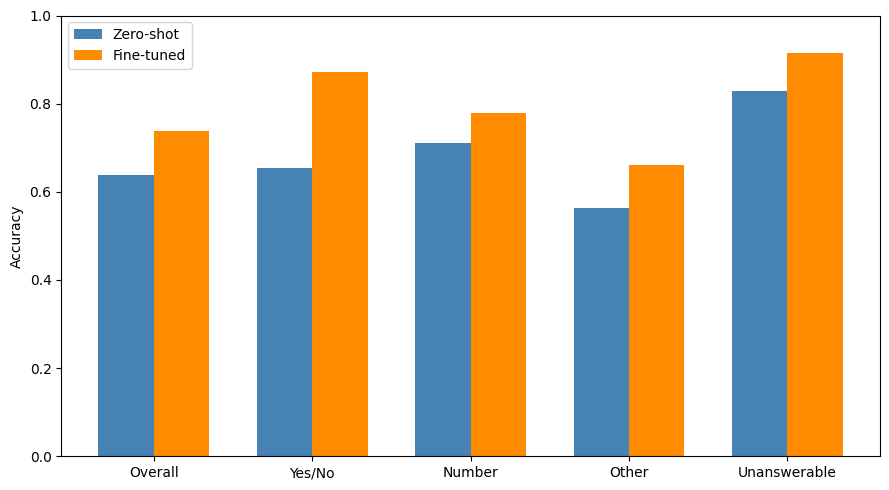

In [35]:
import matplotlib.pyplot as plt
import numpy as np

categories = ['Overall', 'Yes/No', 'Number', 'Other', 'Unanswerable']
zero_shot = [0.638, 0.655, 0.711, 0.564, 0.829]
fine_tuned = [0.737, 0.872, 0.778, 0.661, 0.914]

x = np.arange(len(categories))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, zero_shot, width, label='Zero-shot', color='steelblue')
ax.bar(x + width/2, fine_tuned, width, label='Fine-tuned', color='darkorange')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.0)
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/vizwiz_qwen/results/zeroshot_vs_finetuned.png', dpi=150)
plt.show()


## Gate-enabled vs Gate-disabled Comparison
Produces Figure 12 (Section 5.2) — Gate-enabled vs Gate-disabled Comparison for Overall Accuracy and Answerability F1. 

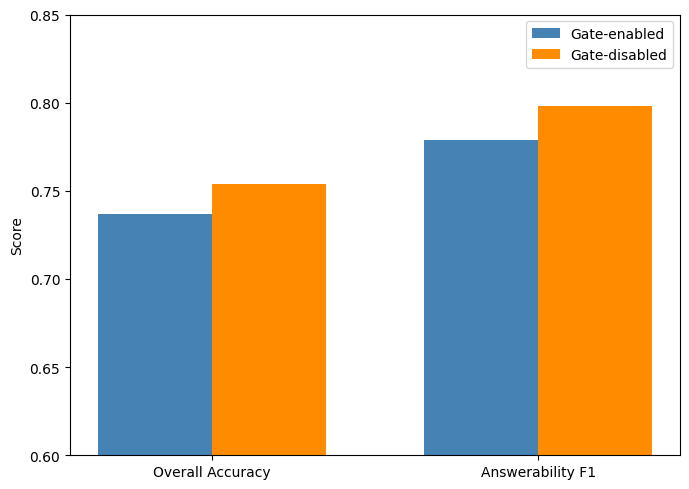

In [36]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Overall Accuracy', 'Answerability F1']
gate_enabled = [0.737, 0.779]
gate_disabled = [0.754, 0.798]

width = 0.35
x = np.arange(len(metrics))
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width/2, gate_enabled, width, label='Gate-enabled', color='steelblue')
ax.bar(x + width/2, gate_disabled, width, label='Gate-disabled', color='darkorange')
ax.set_ylabel('Score')
ax.set_ylim(0.6, 0.85)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/vizwiz_qwen/results/gate_comparison.png', dpi=150)
plt.show()

## Cross-lingual Verification
Produces Figure 13 (Section 5.3) —  Language-match and Content-consistency Rates by Language.

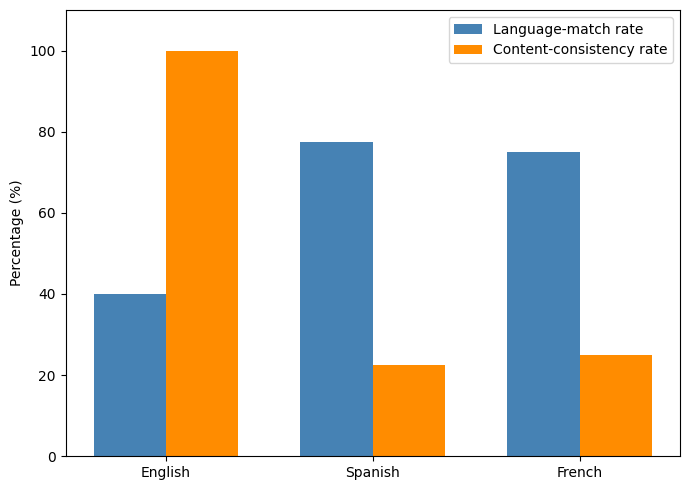

In [37]:
languages = ['English', 'Spanish', 'French']
lang_match = [40.0, 77.5, 75.0]
content_consistent = [100.0, 22.5, 25.0]

x = np.arange(len(languages))
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width/2, lang_match, width, label='Language-match rate', color='steelblue')
ax.bar(x + width/2, content_consistent, width, label='Content-consistency rate', color='darkorange')
ax.set_ylabel('Percentage (%)')
ax.set_ylim(0, 110)
ax.set_xticks(x)
ax.set_xticklabels(languages)
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/vizwiz_qwen/results/crosslingual.png', dpi=150)
plt.show()